### 1. Librerias

In [1]:
import pandas as pd
import numpy as np
import warnings
import time
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### 2. Carga de datos

In [2]:
ruta_archivo = "PRECIOSPI.xlsx"

# Leer Excel sin asumir encabezados
df_raw = pd.read_excel(ruta_archivo, header=None)

# Extraer nombres de los activos
tickers = df_raw.iloc[3, 1:].astype(str).tolist()

# Limpiar nombres
tickers = [
    t.replace(" US Equity", "").replace(" Index", "")
    for t in tickers
]

# Extraer datos históricos
df = df_raw.iloc[6:].copy()

# Asignar nombres de columnas
df.columns = ["Date"] + tickers

# Convertir fechas
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convertir precios a valores numéricos
for col in tickers:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Eliminar filas sin fecha
df = df.dropna(subset=["Date"])

# Ordenar cronológicamente
df = df.sort_values("Date")

# Establecer fecha como índice
df = df.set_index("Date")

print("Datos cargados correctamente.")
print(f"Dimensiones: {df.shape}")

print("\nActivos disponibles:")
for i, activo in enumerate(tickers, start=1):
    print(f"{i}. {activo}")

print("\nPeriodo:")
print(f"Desde: {df.index.min().date()}")
print(f"Hasta: {df.index.max().date()}")

Datos cargados correctamente.
Dimensiones: (2805, 10)

Activos disponibles:
1. AAPL
2. NVDA
3. MSFT
4. GOOGL
5. SPX
6. NDX
7. CBNK
8. NBI
9. AMZN
10. DJI

Periodo:
Desde: 2016-01-01
Hasta: 2026-10-01


### 3. Revisión datos faltantes

In [3]:
faltantes = df.isna().sum()

print("Valores faltantes por activo:")
display(faltantes.to_frame("Valores faltantes"))

print("\nTotal de valores faltantes:", faltantes.sum())

Valores faltantes por activo:


,Valores faltantes
AAPL,0
NVDA,0
MSFT,0
GOOGL,0
SPX,0
NDX,0
CBNK,0
NBI,0
AMZN,0
DJI,0



Total de valores faltantes: 0


### 4. Estadisticas descriptivas

In [4]:
estadisticas = df.describe().T

estadisticas

,count,mean,std,min,25%,50%,75%,max
AAPL,2805.0,128.703750,83.431149,22.5850,45.6350,131.970,187.430,341.07
NVDA,2805.0,47.686282,65.074394,0.6305,4.7623,14.036,61.031,235.74
MSFT,2805.0,243.427105,143.743521,48.4300,105.3700,239.820,374.370,542.07
GOOGL,2805.0,117.444997,82.410555,34.0570,55.4950,96.410,145.940,402.62
SPX,2805.0,4014.331800,1532.652392,1829.0800,2738.9700,3855.760,4864.600,7798.99
NDX,2805.0,12930.231405,6863.456546,3947.8000,7014.5500,12033.620,17210.890,30732.40
CBNK,2805.0,3888.738738,707.661332,2136.7200,3501.5300,3911.550,4355.510,5553.21
NBI,2805.0,4093.268367,910.227640,2524.4400,3373.6300,4056.990,4558.270,7404.92
AMZN,2805.0,129.035292,64.027890,24.1040,82.9410,124.250,174.345,284.02
DJI,2805.0,31768.087444,9271.195834,15660.1800,24815.0400,31490.070,37775.380,54349.12


### 5. Series de tiempo

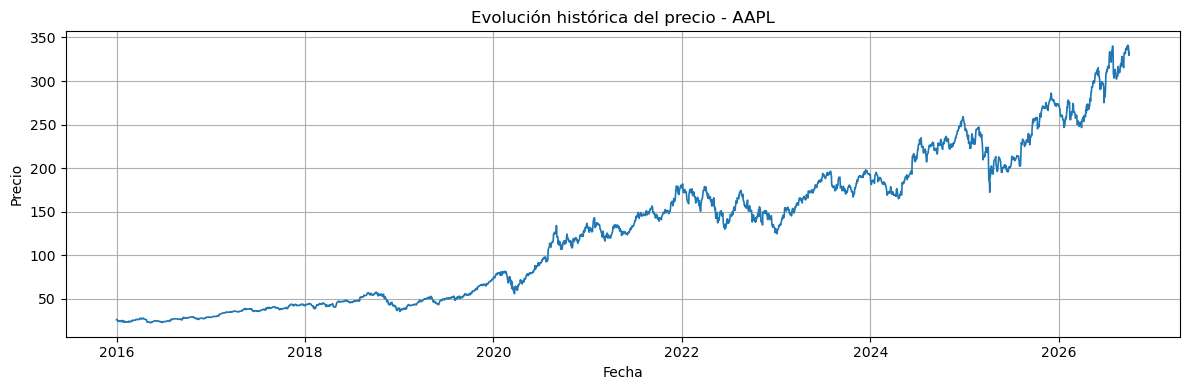

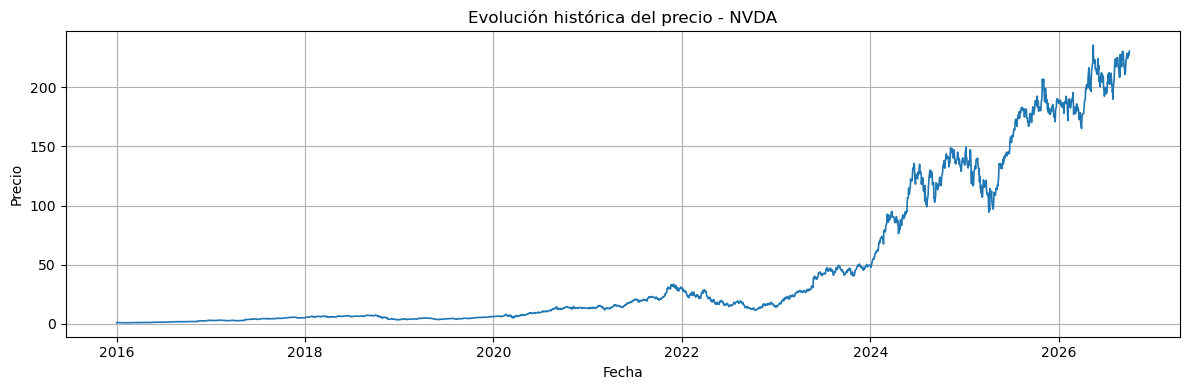

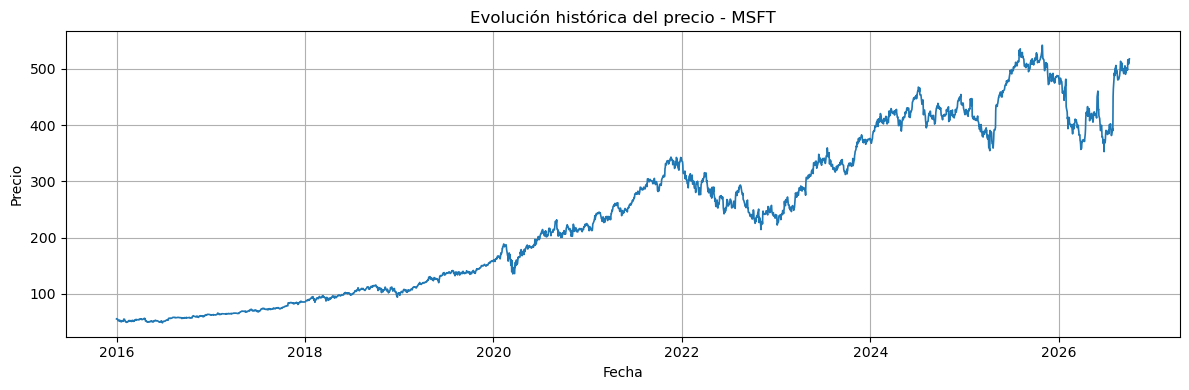

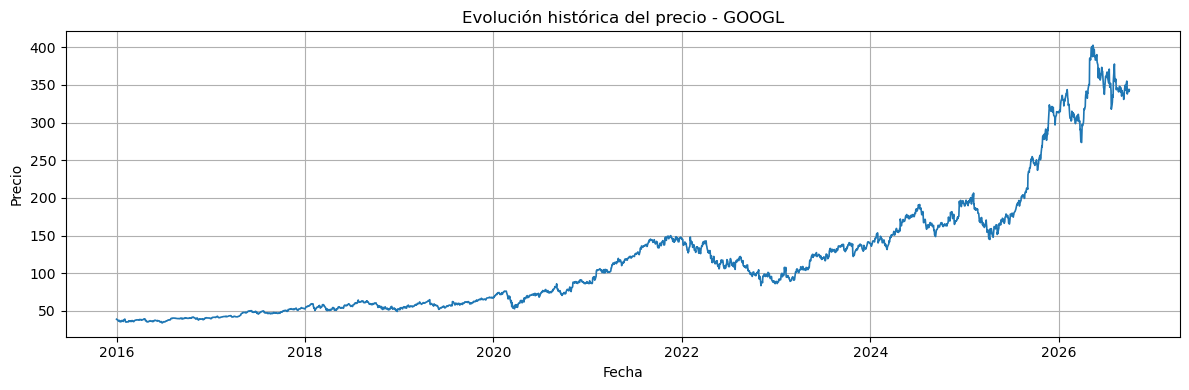

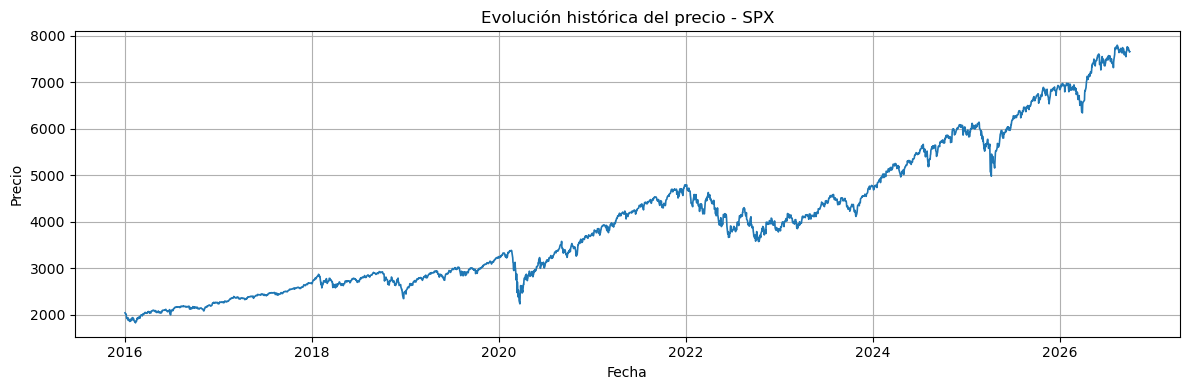

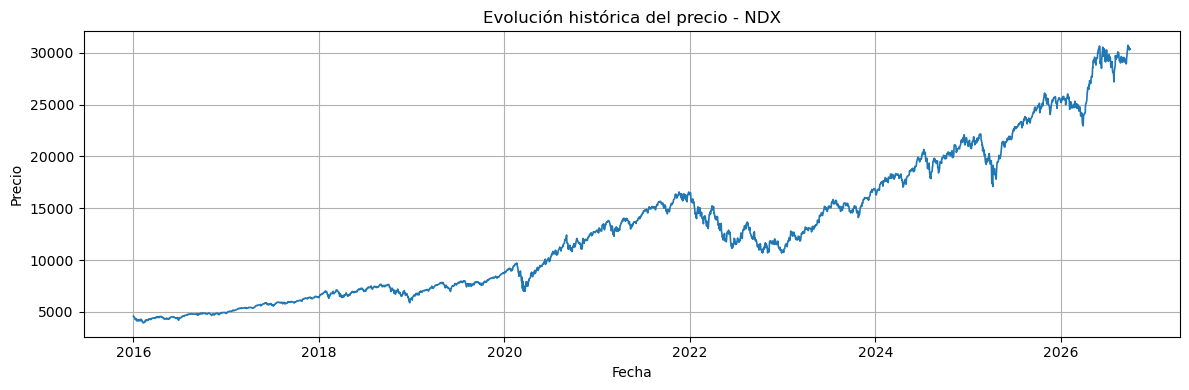

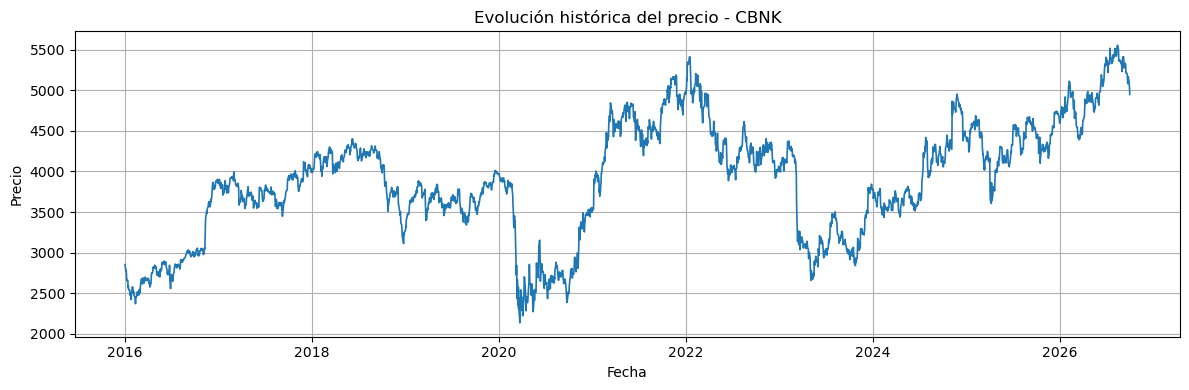

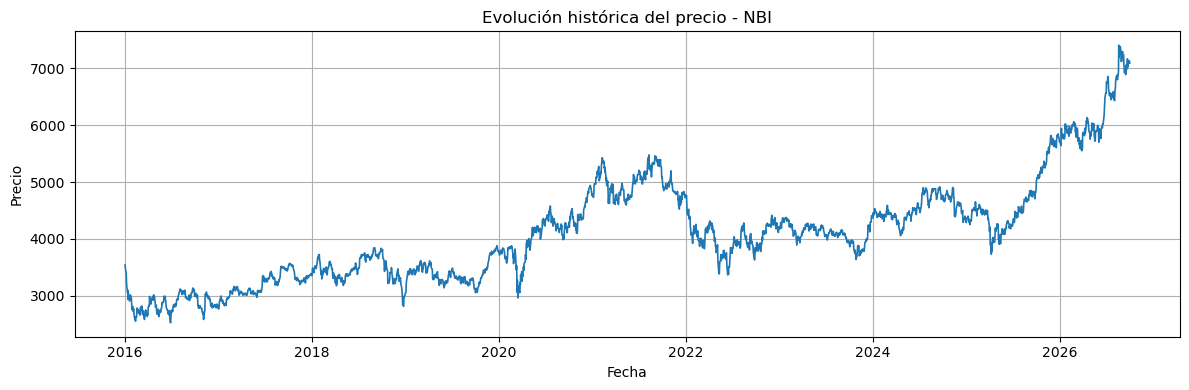

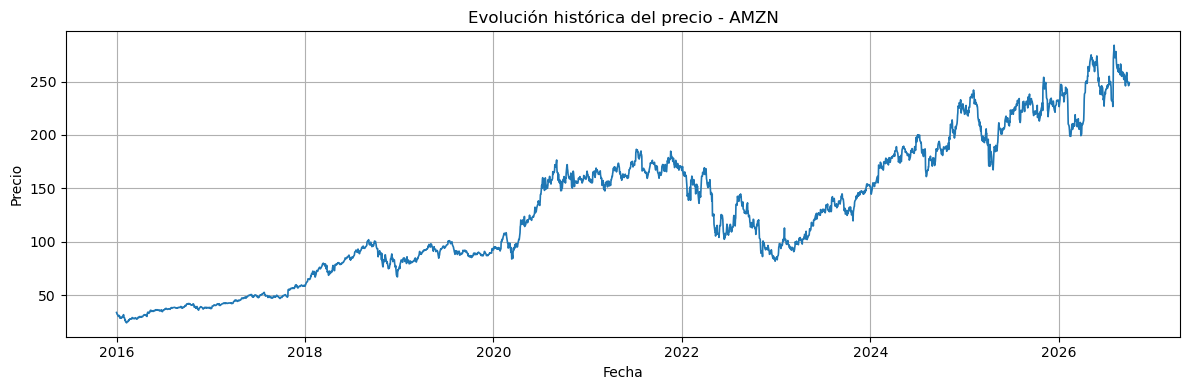

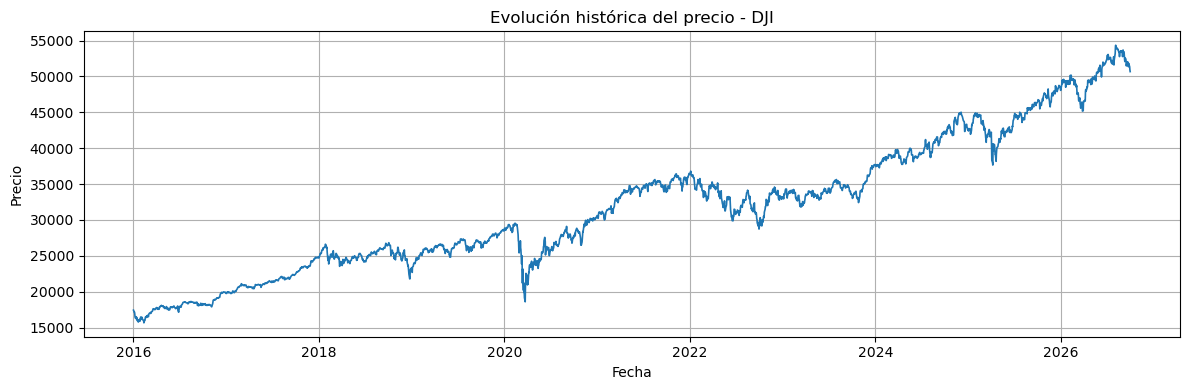

In [5]:
for activo in tickers:
    
    plt.figure(figsize=(12, 4))
    
    plt.plot(
        df.index,
        df[activo],
        linewidth=1.2
    )
    
    plt.title(f"Evolución histórica del precio - {activo}")
    plt.xlabel("Fecha")
    plt.ylabel("Precio")
    plt.tight_layout()
    plt.show()

### 6. División de datos

In [6]:
train_size = int(len(df) * 0.80)

train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

print("ENTRENAMIENTO")
print(
    train.index.min().date(),
    "-",
    train.index.max().date()
)

print("\nPRUEBA")
print(
    test.index.min().date(),
    "-",
    test.index.max().date()
)

print("\nObservaciones entrenamiento:", len(train))
print("Observaciones prueba:", len(test))

ENTRENAMIENTO
2016-01-01 - 2024-08-07

PRUEBA
2024-08-08 - 2026-10-01

Observaciones entrenamiento: 2244
Observaciones prueba: 561


### 7. Prueba ADF - Estacionariedad

In [7]:
resultados_adf = []

for activo in tickers:
    
    serie = train[activo].dropna()
    
    resultado = adfuller(serie)
    
    resultados_adf.append({
        "Activo": activo,
        "ADF Statistic": resultado[0],
        "p-value": resultado[1],
        "Estacionaria (5%)": resultado[1] < 0.05
    })

df_adf = pd.DataFrame(resultados_adf)

display(df_adf)

,Activo,ADF Statistic,p-value,Estacionaria (5%)
0,AAPL,-0.108860,0.948549,False
1,NVDA,-0.012188,0.957512,False
2,MSFT,-0.062665,0.953033,False
3,GOOGL,-0.129311,0.946440,False
4,SPX,-0.588280,0.873608,False
5,NDX,-0.429337,0.905084,False
6,CBNK,-2.583946,0.096361,False
7,NBI,-1.724225,0.418676,False
8,AMZN,-1.409805,0.577566,False
9,DJI,-1.322117,0.618994,False


### 8. Determinar numero de diferenciaciones (d)

In [8]:
def obtener_d_optimo(serie, max_d=2, alpha=0.05):
    
    serie_actual = serie.dropna().copy()
    
    for d in range(max_d + 1):
        
        p_value = adfuller(serie_actual)[1]
        
        if p_value < alpha:
            return d
        
        serie_actual = serie_actual.diff().dropna()
    
    return max_d

resultados_d = []

for activo in tickers:
    
    d_optimo = obtener_d_optimo(train[activo])
    
    resultados_d.append({
        "Activo": activo,
        "d óptimo": d_optimo
    })

df_d = pd.DataFrame(resultados_d)

display(df_d)

,Activo,d óptimo
0,AAPL,1
1,NVDA,1
2,MSFT,1
3,GOOGL,1
4,SPX,1
5,NDX,1
6,CBNK,1
7,NBI,1
8,AMZN,1
9,DJI,1


### 9. Series diferenciadas

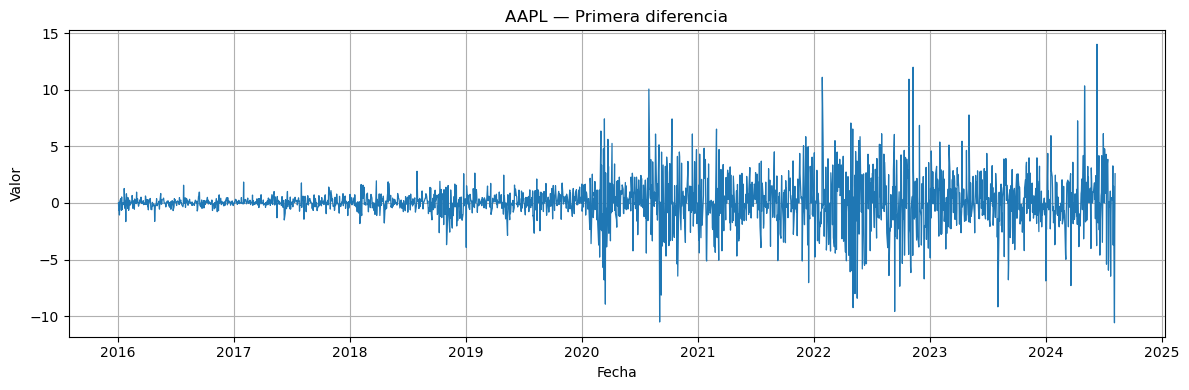

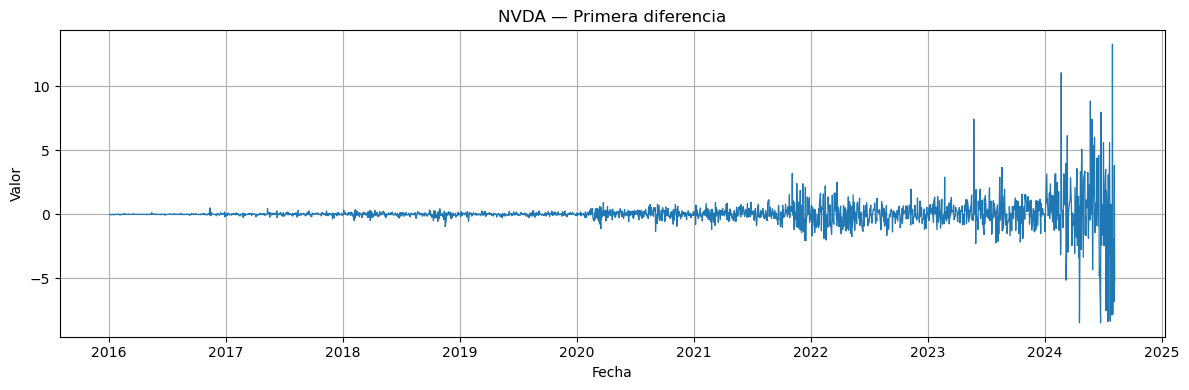

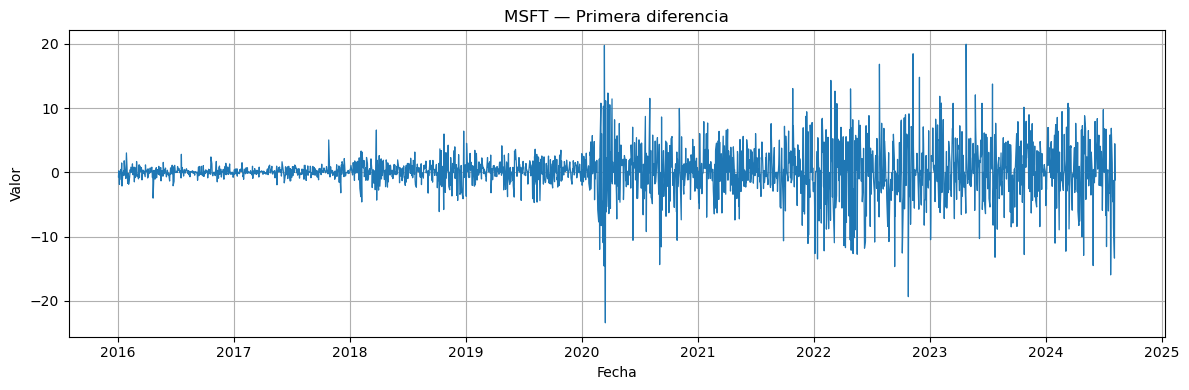

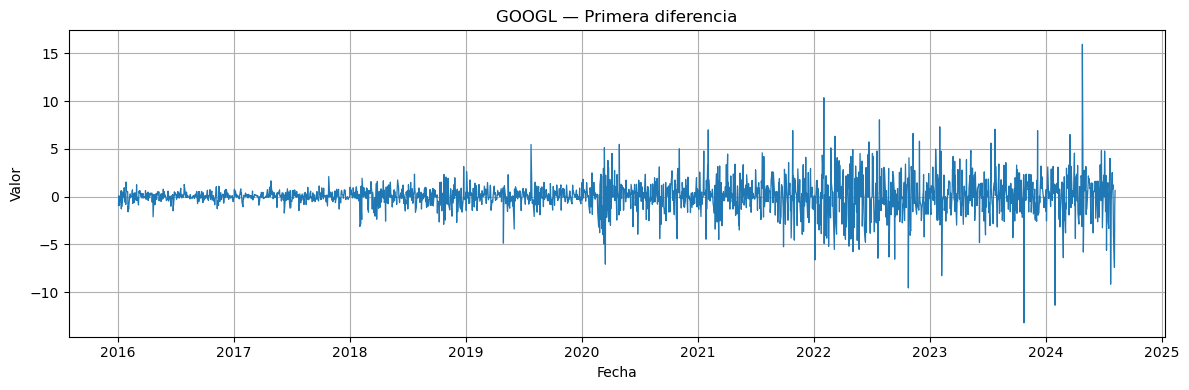

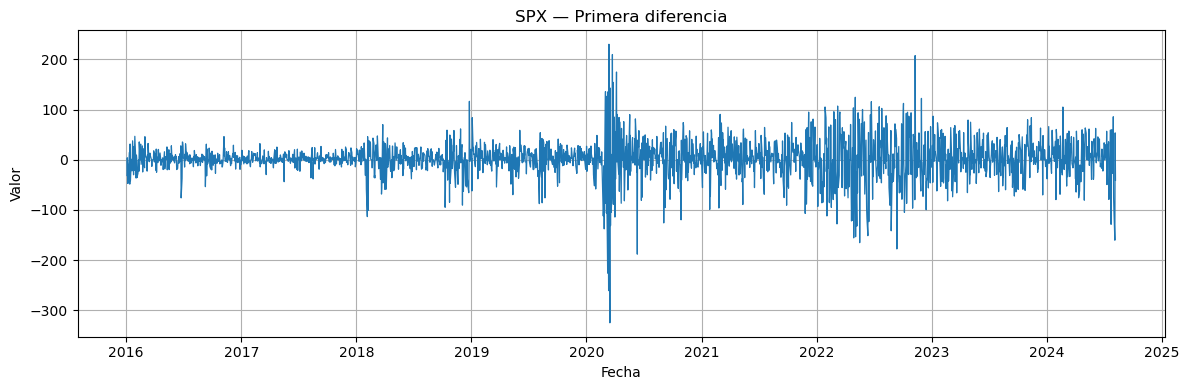

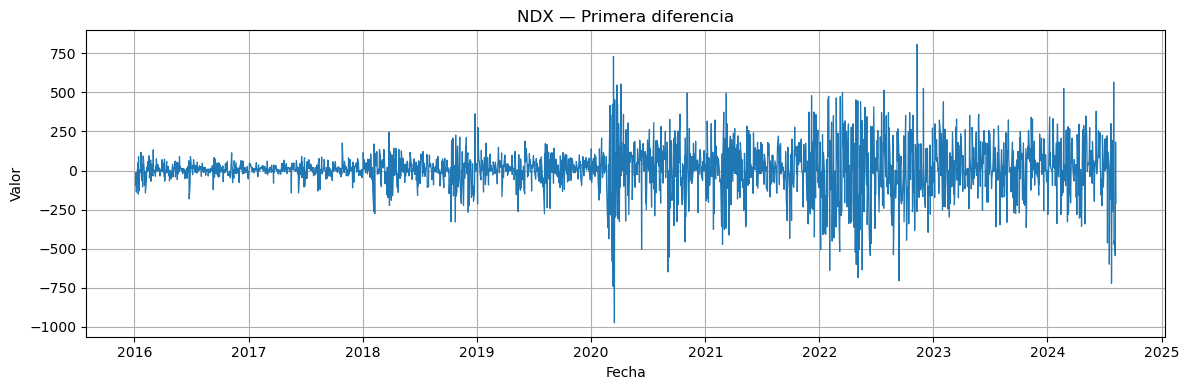

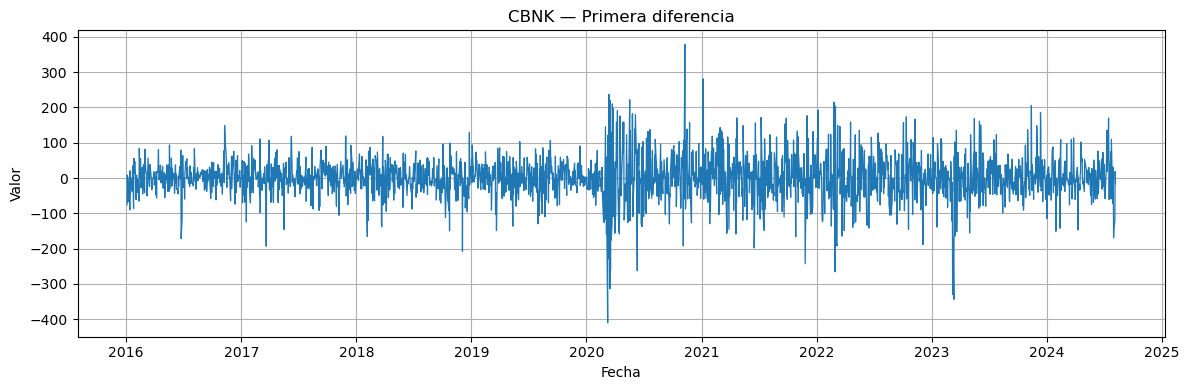

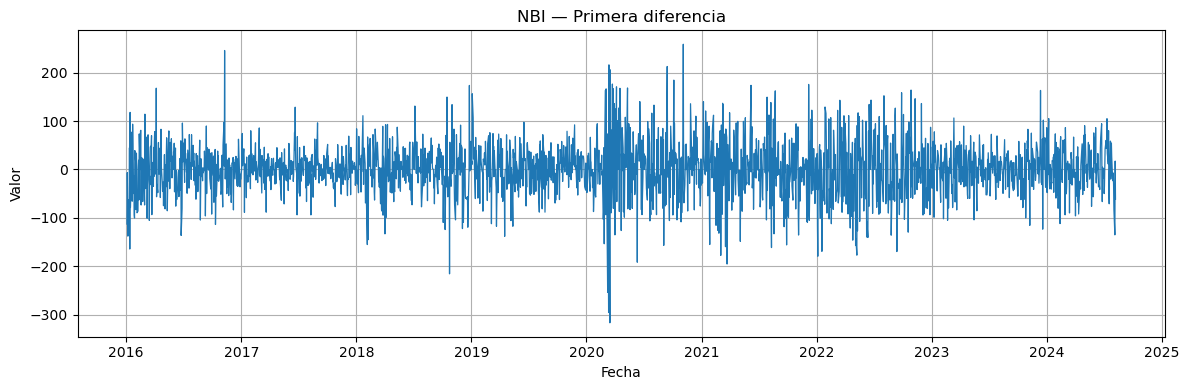

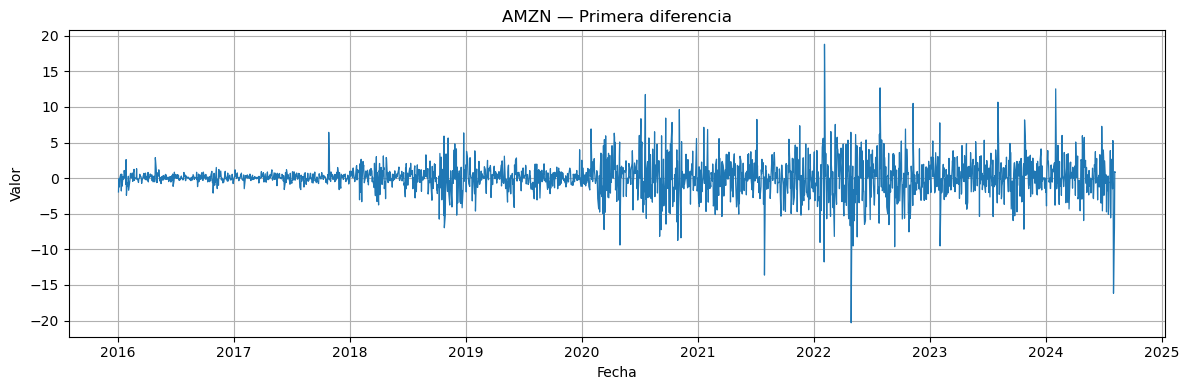

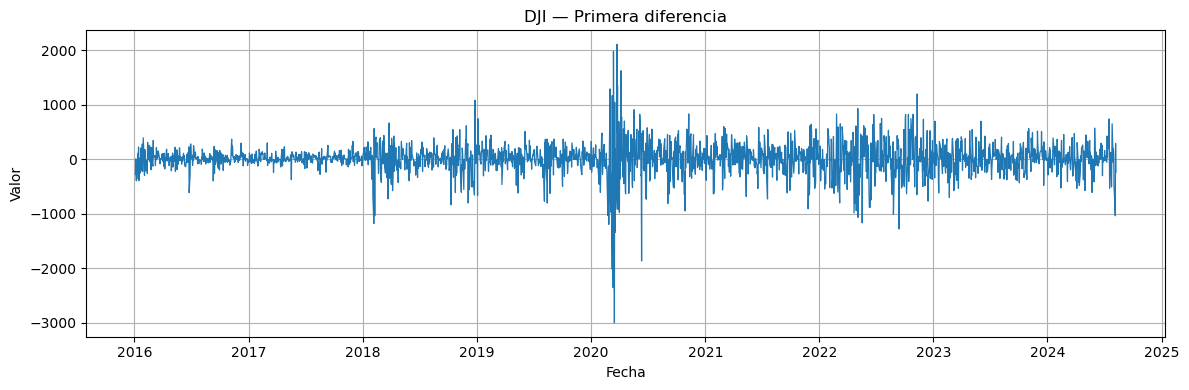

In [9]:
for activo in tickers:
    
    d = int(
        df_d.loc[
            df_d["Activo"] == activo,
            "d óptimo"
        ].iloc[0]
    )
    
    serie = train[activo]
    
    if d == 0:
        serie_transformada = serie
        titulo = "Serie original"
    elif d == 1:
        serie_transformada = serie.diff().dropna()
        titulo = "Primera diferencia"
    else:
        serie_transformada = serie.diff().diff().dropna()
        titulo = "Segunda diferencia"
    
    plt.figure(figsize=(12, 4))
    
    plt.plot(
        serie_transformada,
        linewidth=0.9
    )
    
    plt.title(
        f"{activo} — {titulo}"
    )
    
    plt.xlabel("Fecha")
    plt.ylabel("Valor")
    plt.tight_layout()
    plt.show()

### 10. Prueba Jung-Box

In [22]:
resultados_memoria = []
nivel_significancia = 0.05

for activo in tickers:
    # 1. Obtener la serie y aplicarle las diferencias necesarias para que sea estacionaria
    d = int(df_d.loc[df_d["Activo"] == activo, "d óptimo"].iloc[0])
    serie = train[activo].dropna()
    
    if d > 0:
        serie = serie.diff(d).dropna()
        
    # 2. Aplicar la prueba de Ljung-Box sobre la serie estacionaria
    # Evaluamos si en los primeros 10 rezagos hay comportamiento conjunto
    prueba = acorr_ljungbox(serie, lags=[10], return_df=True)
    pval_10 = prueba.loc[10, "lb_pvalue"]
    
    # Si p-value < 0.05, los rezagos SÍ tienen información útil
    hay_comportamiento = "Sí" if pval_10 < nivel_significancia else "No (Ruido Blanco)"
    
    resultados_memoria.append({
        "Activo": activo,
        "d aplicado": d,
        "p-value (Ljung-Box lag 10)": round(pval_10, 4),
        "¿Rezagos con comportamiento?": hay_comportamiento
    })

df_memoria = pd.DataFrame(resultados_memoria)
display(df_memoria)

,Activo,d aplicado,p-value (Ljung-Box lag 10),¿Rezagos con comportamiento?
0,AAPL,1,0.0002,Sí
1,NVDA,1,0.0000,Sí
2,MSFT,1,0.0000,Sí
3,GOOGL,1,0.0005,Sí
4,SPX,1,0.0000,Sí
5,NDX,1,0.0000,Sí
6,CBNK,1,0.0000,Sí
7,NBI,1,0.0011,Sí
8,AMZN,1,0.0270,Sí
9,DJI,1,0.0000,Sí


### 11. PACF y ACF 

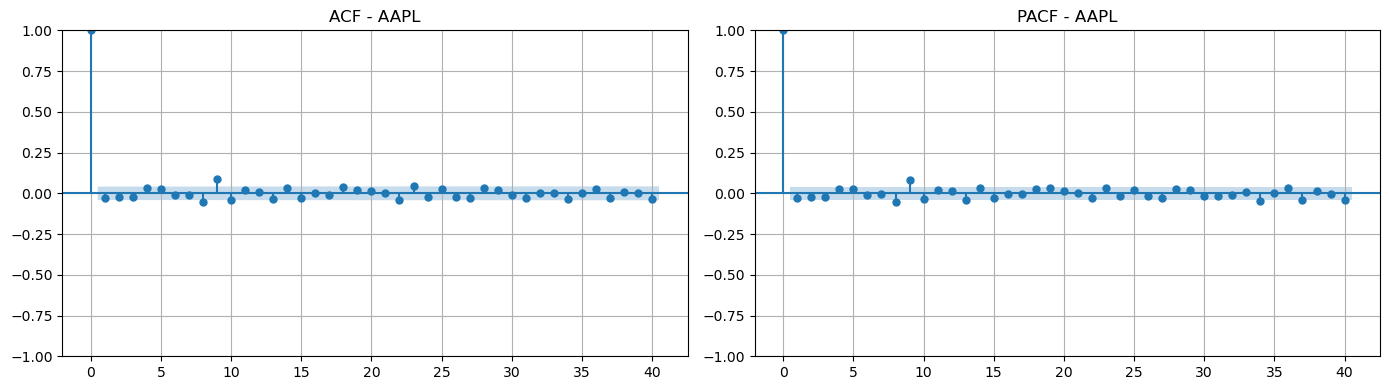

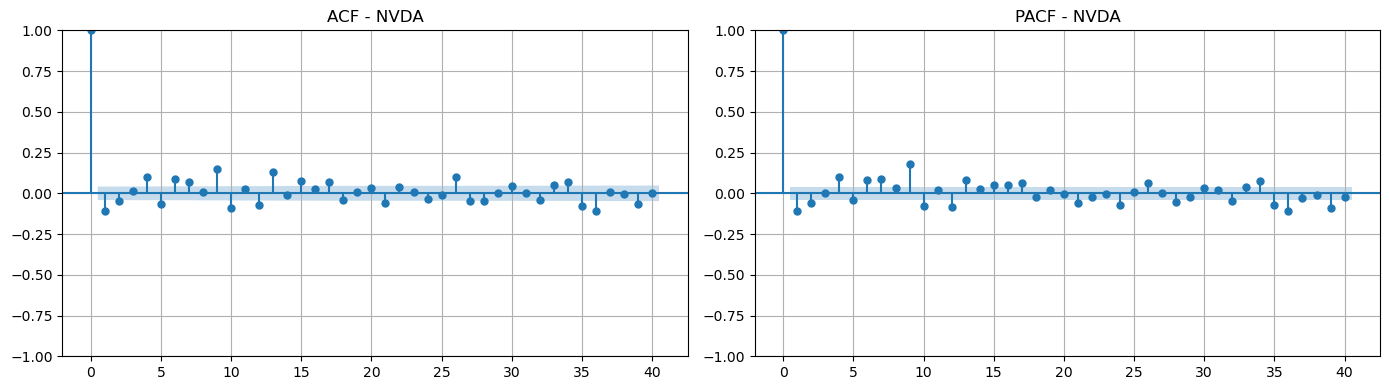

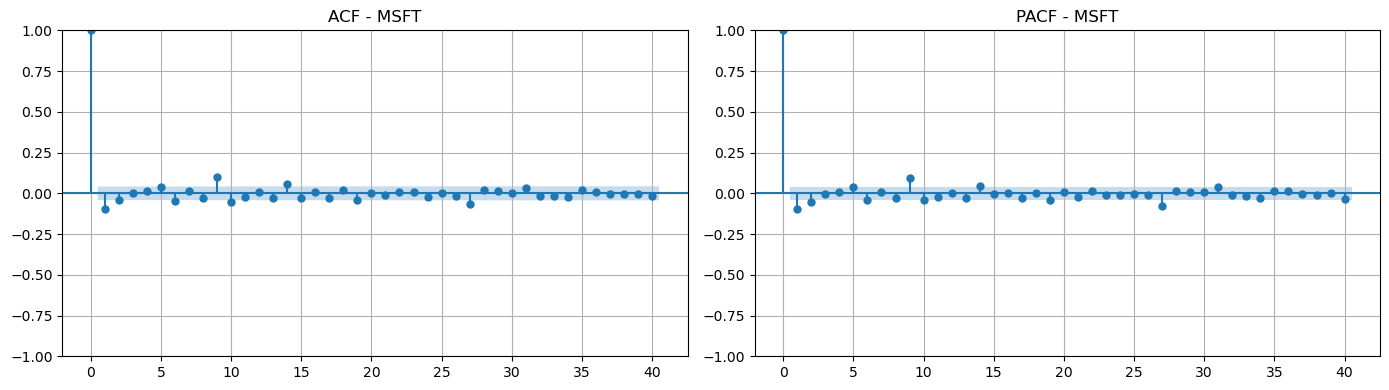

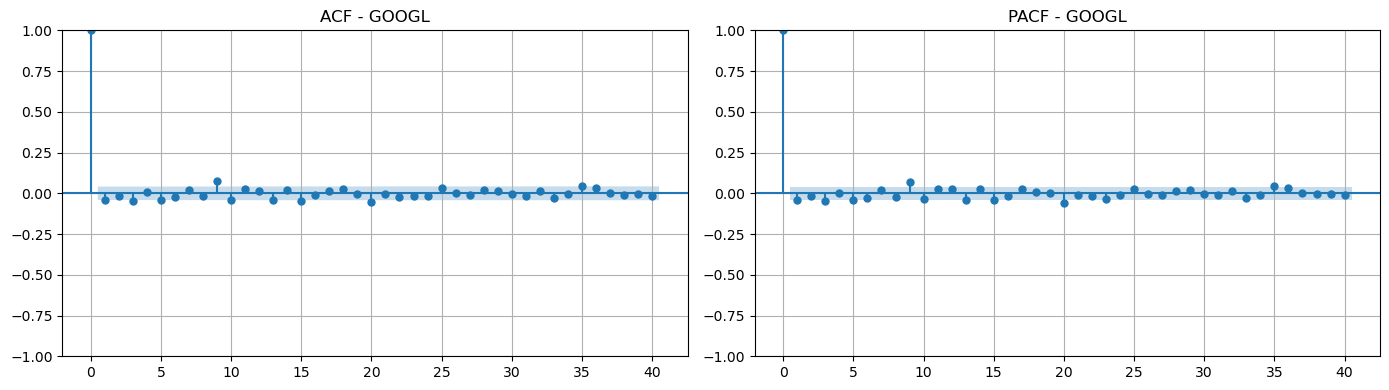

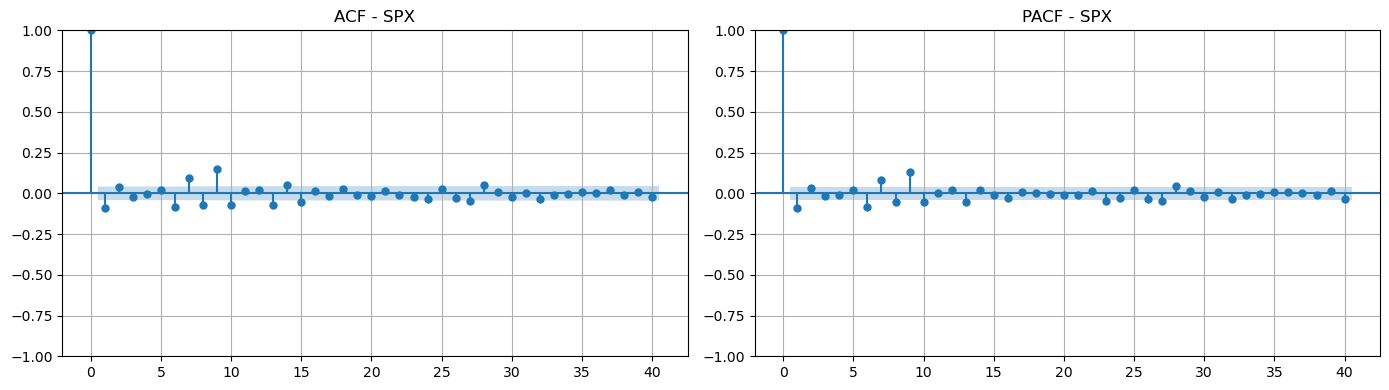

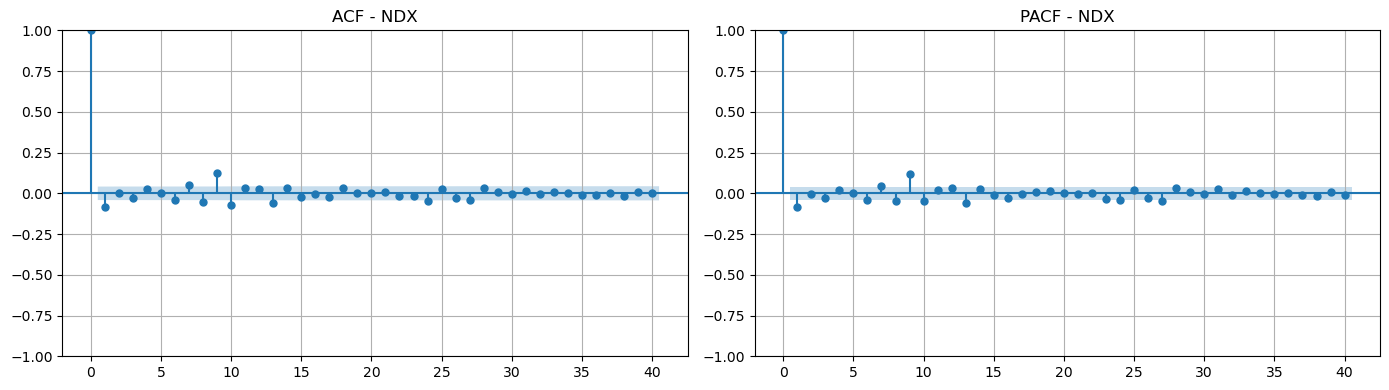

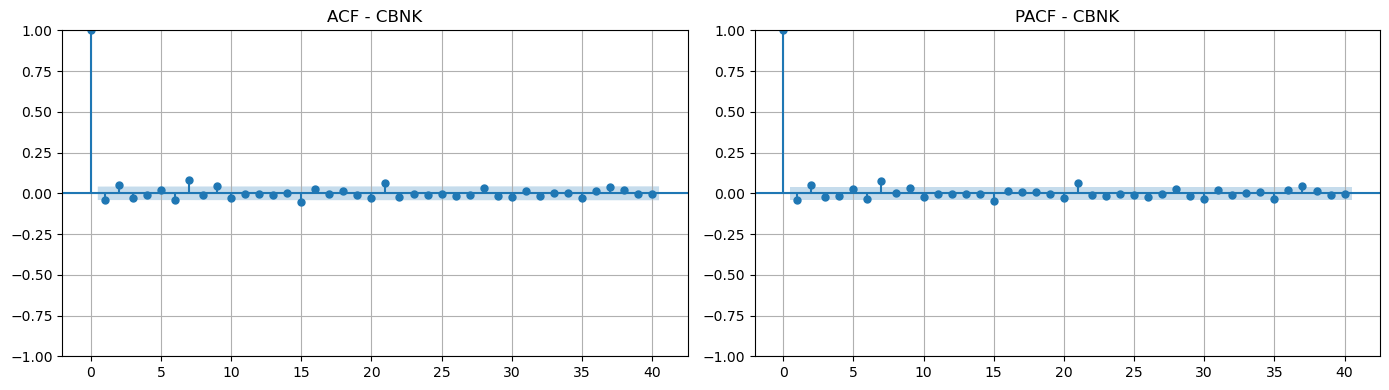

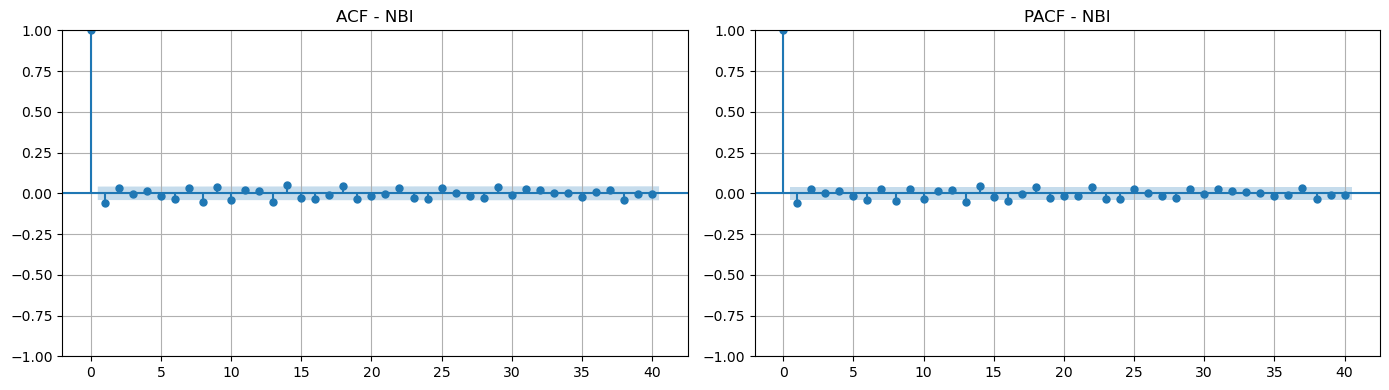

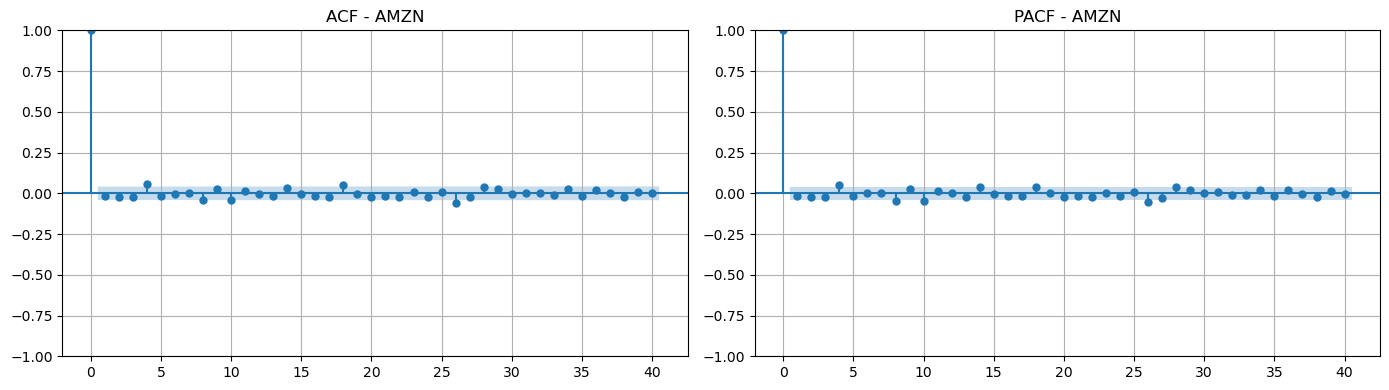

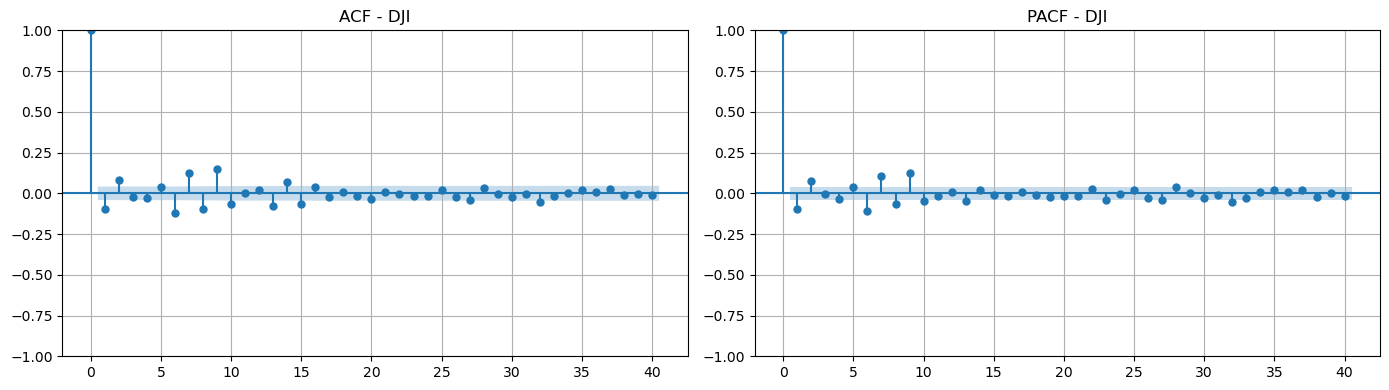

In [10]:
for activo in tickers:
    
    d = int(
        df_d.loc[
            df_d["Activo"] == activo,
            "d óptimo"
        ].iloc[0]
    )
    
    serie = train[activo].dropna()
    
    if d > 0:
        serie = serie.diff(d).dropna()
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    plot_acf(
        serie,
        lags=40,
        ax=axes[0]
    )
    
    plot_pacf(
        serie,
        lags=40,
        ax=axes[1],
        method="ywm"
    )
    
    axes[0].set_title(f"ACF - {activo}")
    axes[1].set_title(f"PACF - {activo}")
    
    plt.tight_layout()
    plt.show()

### 12. Encontrar ARIMA adecuado

In [11]:
# 11. Encontrar ARIMA adecuado (VERSIÓN ESTRICTA CON SIGNIFICANCIA)
def optimizar_arima(serie, d, max_p=5, max_q=5, alpha=0.05):
    
    mejor_aic = np.inf
    mejor_bic = np.inf
    mejor_orden = None
    mejor_modelo = None
    
    # Variables de respaldo (fallback) por si ningún modelo cumple la regla
    mejor_aic_general = np.inf
    mejor_bic_general = np.inf
    mejor_orden_general = None
    mejor_modelo_general = None
    
    candidatos = []
    
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            
            try:
                modelo = ARIMA(serie, order=(p, d, q))
                resultado = modelo.fit()
                
                # --- NUEVA LÓGICA DE SIGNIFICANCIA ---
                # Extraemos los p-values del modelo
                p_values = resultado.pvalues
                
                # Filtramos solo los coeficientes que empiezan por 'ar.' o 'ma.'
                coefs_arma = [col for col in p_values.index if col.startswith('ar.') or col.startswith('ma.')]
                
                if len(coefs_arma) > 0:
                    # Evaluamos si TODOS los rezagos AR y MA son menores al 5% (0.05)
                    todos_significativos = (p_values[coefs_arma] < alpha).all()
                else:
                    # Si el modelo es ARIMA(0, d, 0), no hay parámetros extra que evaluar
                    todos_significativos = True
                # -------------------------------------
                
                candidatos.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": resultado.aic,
                    "BIC": resultado.bic,
                    "Todos_Significativos": "Sí" if todos_significativos else "No"
                })
                
                # Guardar el mejor modelo GENERAL (sin restricciones, como respaldo)
                if resultado.aic < mejor_aic_general:
                    mejor_aic_general = resultado.aic
                    mejor_bic_general = resultado.bic
                    mejor_orden_general = (p, d, q)
                    mejor_modelo_general = resultado
                
                # Guardar el mejor modelo ESTRICTO (Solo si todos sus parámetros son significativos)
                if todos_significativos and (resultado.aic < mejor_aic):
                    mejor_aic = resultado.aic
                    mejor_bic = resultado.bic
                    mejor_orden = (p, d, q)
                    mejor_modelo = resultado
                    
            except:
                continue
    
    tabla_candidatos = (
        pd.DataFrame(candidatos)
        .sort_values("AIC")
        .reset_index(drop=True)
    )
    
    # Sistema de seguridad: Si el ruido es muy alto y NINGÚN modelo cumple la regla estricta,
    # el algoritmo nos avisa y devuelve el modelo con menor AIC general para que el código no colapse.
    if mejor_modelo is None:
        print("    [Aviso] Ningún modelo tuvo todos sus parámetros significativos. Aplicando AIC estándar.")
        return (mejor_orden_general, mejor_aic_general, mejor_bic_general, mejor_modelo_general, tabla_candidatos)
    
    return (mejor_orden, mejor_aic, mejor_bic, mejor_modelo, tabla_candidatos)

modelos_arima = {}
tablas_candidatos = {}
resultados_modelos = []

inicio = time.perf_counter()

for activo in tickers:
    
    print(f"Optimizando {activo}...")
    
    serie = train[activo].dropna()
    d = int(df_d.loc[df_d["Activo"] == activo, "d óptimo"].iloc[0])
    
    (mejor_orden, mejor_aic, mejor_bic, mejor_modelo, tabla_candidatos) = optimizar_arima(
        serie, d=d, max_p=5, max_q=5, alpha=0.05
    )
    
    modelos_arima[activo] = mejor_modelo
    tablas_candidatos[activo] = tabla_candidatos
    
    resultados_modelos.append({
        "Activo": activo,
        "p": mejor_orden[0],
        "d": mejor_orden[1],
        "q": mejor_orden[2],
        "Orden": mejor_orden,
        "AIC": mejor_aic,
        "BIC": mejor_bic
    })

tiempo_modelos = time.perf_counter() - inicio
print(f"\nOptimización terminada en {tiempo_modelos/60:.2f} minutos.")

Optimizando AAPL...
Optimizando NVDA...
Optimizando MSFT...
Optimizando GOOGL...
Optimizando SPX...
Optimizando NDX...
Optimizando CBNK...
Optimizando NBI...
Optimizando AMZN...
Optimizando DJI...

Optimización terminada en 14.31 minutos.


In [12]:
for activo in tickers:
    
    print(f"\n{'='*60}")
    print(f"TOP 5 MODELOS — {activo}")
    print(f"{'='*60}")
    
    display(
        tablas_candidatos[activo].head(5)
    )


TOP 5 MODELOS — AAPL


,p,d,q,AIC,BIC,Todos_Significativos
0,2,1,5,9440.978601,9486.703157,No
1,2,1,2,9442.504160,9471.082008,Sí
2,5,1,5,9442.646189,9505.517454,Sí
3,2,1,3,9443.288971,9477.582388,No
4,4,1,2,9445.325733,9485.334720,No



TOP 5 MODELOS — NVDA


,p,d,q,AIC,BIC,Todos_Significativos
0,5,1,5,6275.480656,6338.351921,Sí
1,3,1,5,6280.245884,6331.686010,Sí
2,5,1,3,6296.235710,6347.675835,Sí
3,4,1,4,6353.204071,6404.644197,Sí
4,5,1,4,6354.015474,6411.171169,No



TOP 5 MODELOS — MSFT


,p,d,q,AIC,BIC,Todos_Significativos
0,4,1,5,12115.615391,12172.771086,No
1,2,1,5,12117.739586,12163.464143,No
2,5,1,2,12118.401093,12164.125649,No
3,4,1,2,12119.255773,12159.264760,Sí
4,5,1,5,12119.574491,12182.445756,No


... (10 outputs left out)


TOP 5 MODELOS — AMZN


,p,d,q,AIC,BIC,Todos_Significativos
0,2,1,5,10217.151325,10262.875881,No
1,3,1,5,10218.568589,10270.008715,No
2,4,1,2,10219.153896,10259.162883,Sí
3,2,1,4,10219.332192,10259.341179,No
4,2,1,3,10219.987196,10254.280614,Sí



TOP 5 MODELOS — DJI


,p,d,q,AIC,BIC,Todos_Significativos
0,5,1,5,31784.731775,31847.603039,No
1,2,1,5,31785.557619,31831.282175,No
2,4,1,5,31788.870338,31846.026034,No
3,2,1,4,31789.314198,31829.323185,No
4,5,1,2,31789.422026,31835.146582,No


In [13]:
for activo in tickers:
    
    print("\n")
    print("=" * 100)
    print(f"MODELO ARIMA — {activo}")
    print("=" * 100)
    
    display(
        modelos_arima[activo].summary()
    )



MODELO ARIMA — AAPL


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   AAPL   No. Observations:                 2244
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -4716.252
Date:                Wed, 21 Oct 2026   AIC                           9442.504
Time:                        16:13:29   BIC                           9471.082
Sample:                    01-01-2016   HQIC                          9452.937
                         - 08-07-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5106      0.002    261.776      0.000       0.507       0.514
ar.L2         -0.9981      0.002   -547.301      0.000      -1.002      -0.995
ma.L1         -0.5160      0.002   -217.115      0.000      -0.521      -0.511
ma.L2          0.9966      0.003    397.766      0.000       0.992       1.002
sigma2         3.9247      0.059     66.112      0.000       3.808       4.041
===================================================================================
Ljung-Box (L1) (Q):                   1.50   Jarque-Bera (JB):              3326.29
Prob(Q):                              0.22   Prob(JB):                         0.00
Heteroskedasticity (H):              26.27   Skew:                             0.05
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.96
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""



MODELO ARIMA — NVDA


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   NVDA   No. Observations:                 2244
Model:                 ARIMA(5, 1, 5)   Log Likelihood               -3126.740
Date:                Wed, 21 Oct 2026   AIC                           6275.481
Time:                        16:13:29   BIC                           6338.352
Sample:                    01-01-2016   HQIC                          6298.432
                         - 08-07-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.2802      0.033    -39.313      0.000      -1.344      -1.216
ar.L2          0.4027      0.051      7.847      0.000       0.302       0.503
ar.L3          1.0797      0.038     28.398      0.000       1.005       1.154
ar.L4          0.3936      0.053      7.441      0.000       0.290       0.497
ar.L5          0.0975      0.032      3.068      0.002       0.035       0.160
ma.L1          1.2030      0.031     39.206      0.000       1.143       1.263
ma.L2         -0.6070      0.049    -12.423      0.000      -0.703      -0.511
ma.L3         -1.1449      0.036    -32.002      0.000      -1.215      -1.075
ma.L4         -0.1084      0.052     -2.078      0.038      -0.211      -0.006
ma.L5          0.1702      0.029      5.789      0.000       0.113       0.228
sigma2         0.9554      0.007    129.882      0.000       0.941       0.970
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):            107063.25
Prob(Q):                              0.95   Prob(JB):                         0.00
Heteroskedasticity (H):             225.72   Skew:                             0.37
Prob(H) (two-sided):                  0.00   Kurtosis:                        36.84
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""



MODELO ARIMA — MSFT


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   MSFT   No. Observations:                 2244
Model:                 ARIMA(4, 1, 2)   Log Likelihood               -6052.628
Date:                Wed, 21 Oct 2026   AIC                          12119.256
Time:                        16:13:29   BIC                          12159.265
Sample:                    01-01-2016   HQIC                         12133.861
                         - 08-07-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5891      0.014     41.830      0.000       0.561       0.617
ar.L2         -0.9669      0.015    -62.479      0.000      -0.997      -0.937
ar.L3         -0.0670      0.015     -4.519      0.000      -0.096      -0.038
ar.L4         -0.0341      0.014     -2.351      0.019      -0.062      -0.006
ma.L1         -0.6894      0.004   -173.741      0.000      -0.697      -0.682
ma.L2          0.9941      0.004    248.606      0.000       0.986       1.002
sigma2        12.9170      0.225     57.459      0.000      12.476      13.358
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):              1763.48
Prob(Q):                              0.90   Prob(JB):                         0.00
Heteroskedasticity (H):              23.68   Skew:                            -0.26
Prob(H) (two-sided):                  0.00   Kurtosis:                         7.31
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

... (10 outputs left out)



MODELO ARIMA — AMZN


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   AMZN   No. Observations:                 2244
Model:                 ARIMA(4, 1, 2)   Log Likelihood               -5102.577
Date:                Wed, 21 Oct 2026   AIC                          10219.154
Time:                        16:13:29   BIC                          10259.163
Sample:                    01-01-2016   HQIC                         10233.759
                         - 08-07-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.5965      0.035    -45.908      0.000      -1.665      -1.528
ar.L2         -0.9681      0.039    -24.972      0.000      -1.044      -0.892
ar.L3         -0.0843      0.030     -2.802      0.005      -0.143      -0.025
ar.L4         -0.0347      0.017     -2.020      0.043      -0.068      -0.001
ma.L1          1.5837      0.033     48.092      0.000       1.519       1.648
ma.L2          0.9207      0.031     30.101      0.000       0.861       0.981
sigma2         5.5391      0.077     71.878      0.000       5.388       5.690
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):              6374.61
Prob(Q):                              0.98   Prob(JB):                         0.00
Heteroskedasticity (H):               8.92   Skew:                            -0.24
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.25
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""



MODELO ARIMA — DJI


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                    DJI   No. Observations:                 2244
Model:                 ARIMA(3, 1, 2)   Log Likelihood              -15888.927
Date:                Wed, 21 Oct 2026   AIC                          31789.854
Time:                        16:13:29   BIC                          31824.148
Sample:                    01-01-2016   HQIC                         31802.373
                         - 08-07-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.6393      0.035    -46.456      0.000      -1.708      -1.570
ar.L2         -0.7256      0.044    -16.472      0.000      -0.812      -0.639
ar.L3          0.0613      0.015      4.124      0.000       0.032       0.090
ma.L1          1.5866      0.033     47.840      0.000       1.522       1.652
ma.L2          0.7071      0.031     22.683      0.000       0.646       0.768
sigma2      8.324e+04   1236.605     67.313      0.000    8.08e+04    8.57e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):              6586.81
Prob(Q):                              0.96   Prob(JB):                         0.00
Heteroskedasticity (H):               3.37   Skew:                            -0.81
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.24
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

### 13. Residuos

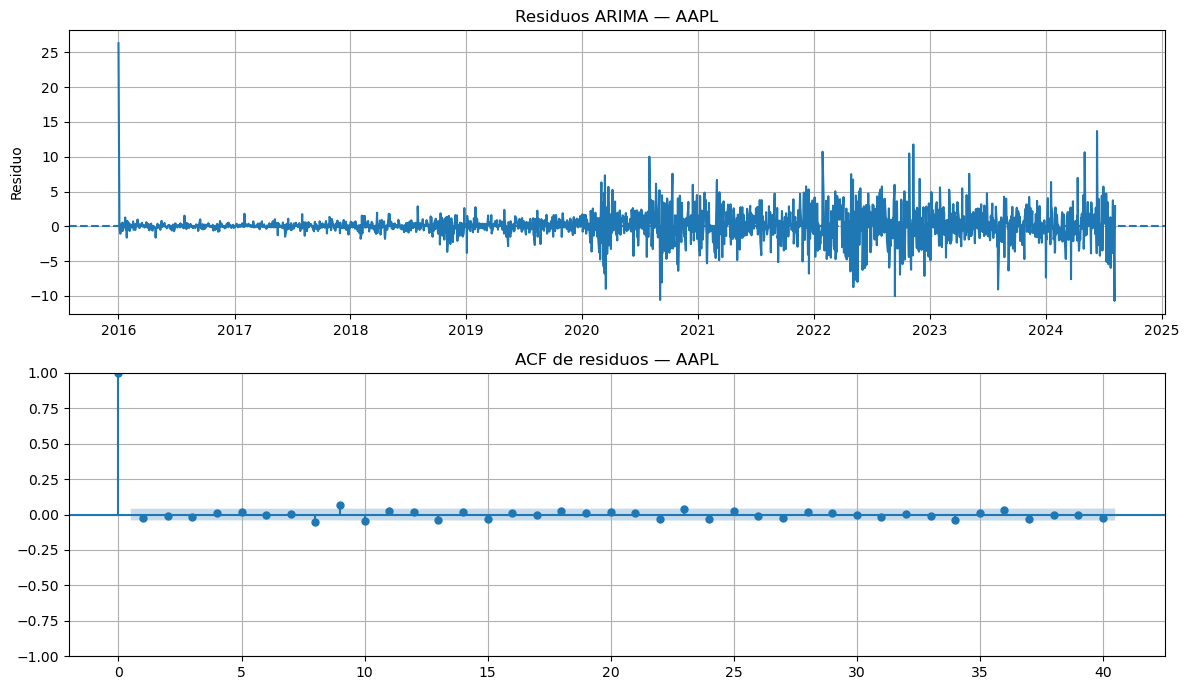

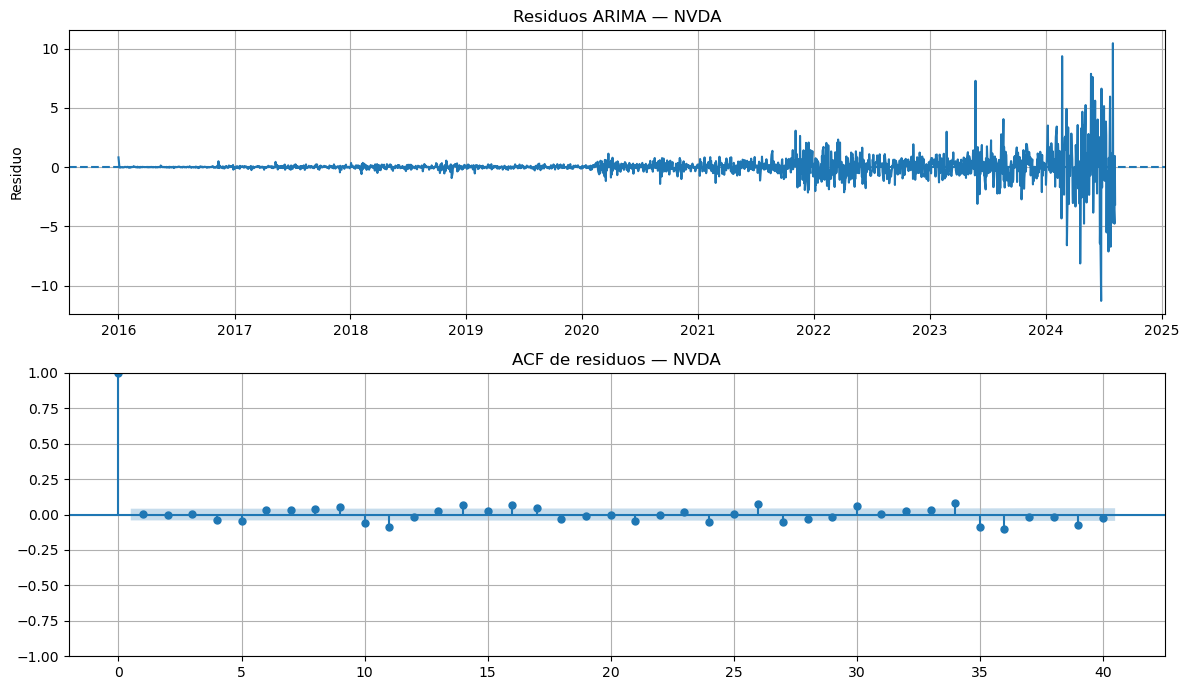

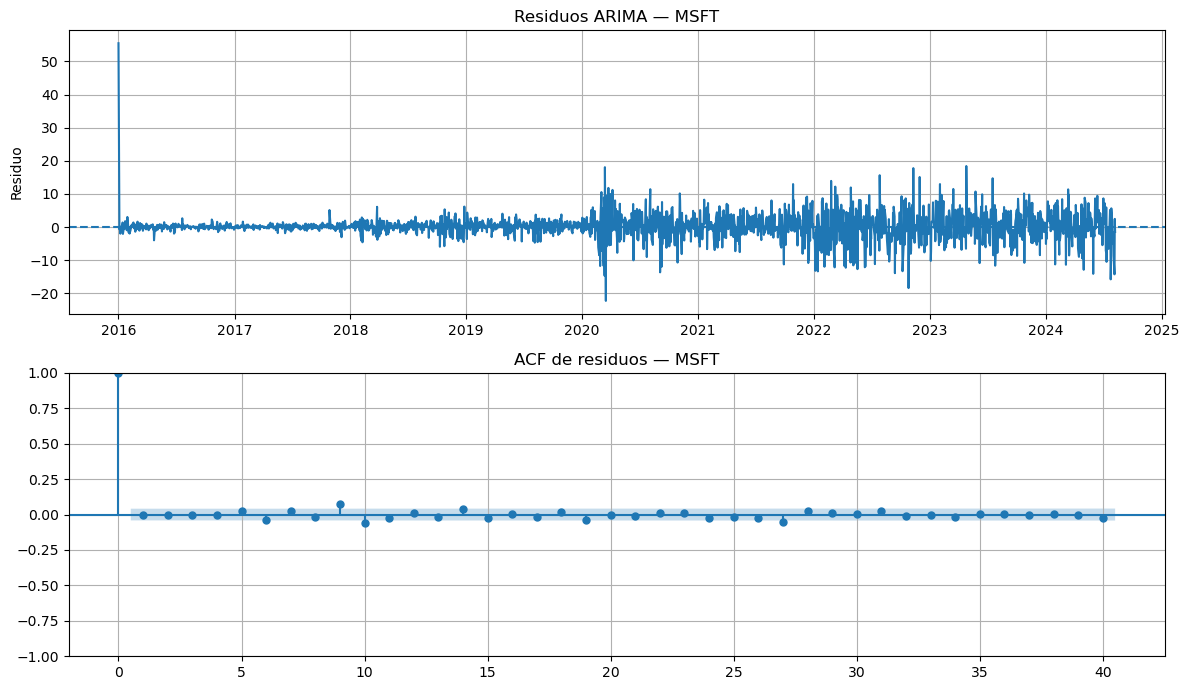

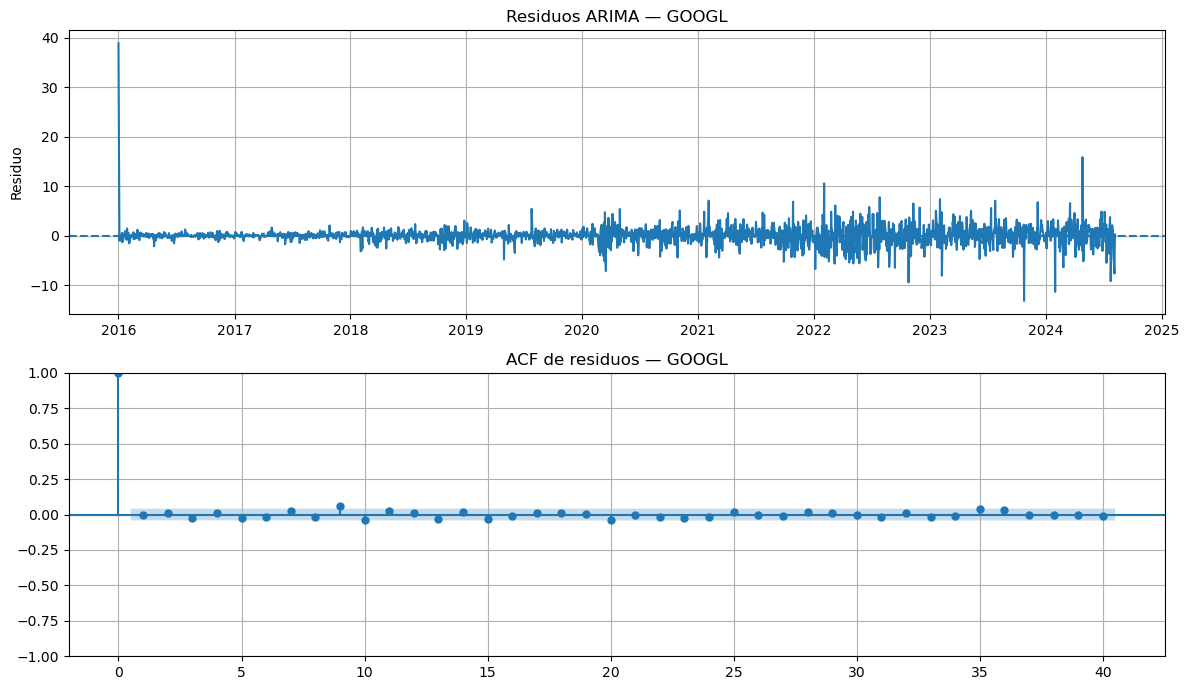

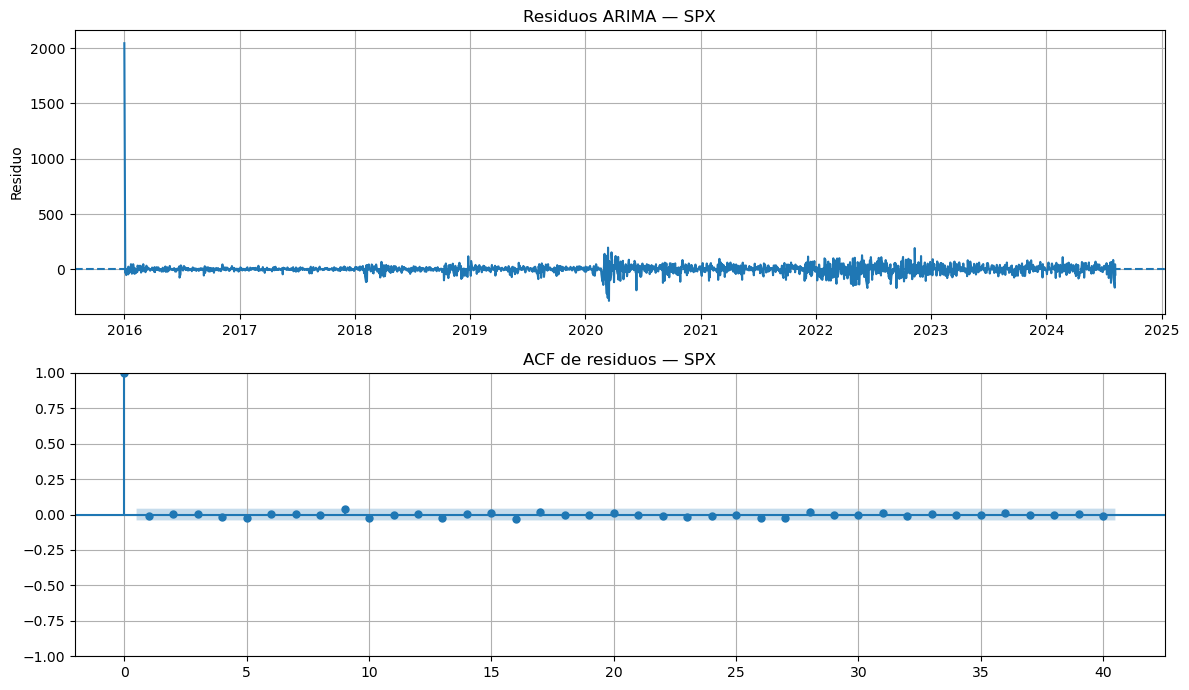

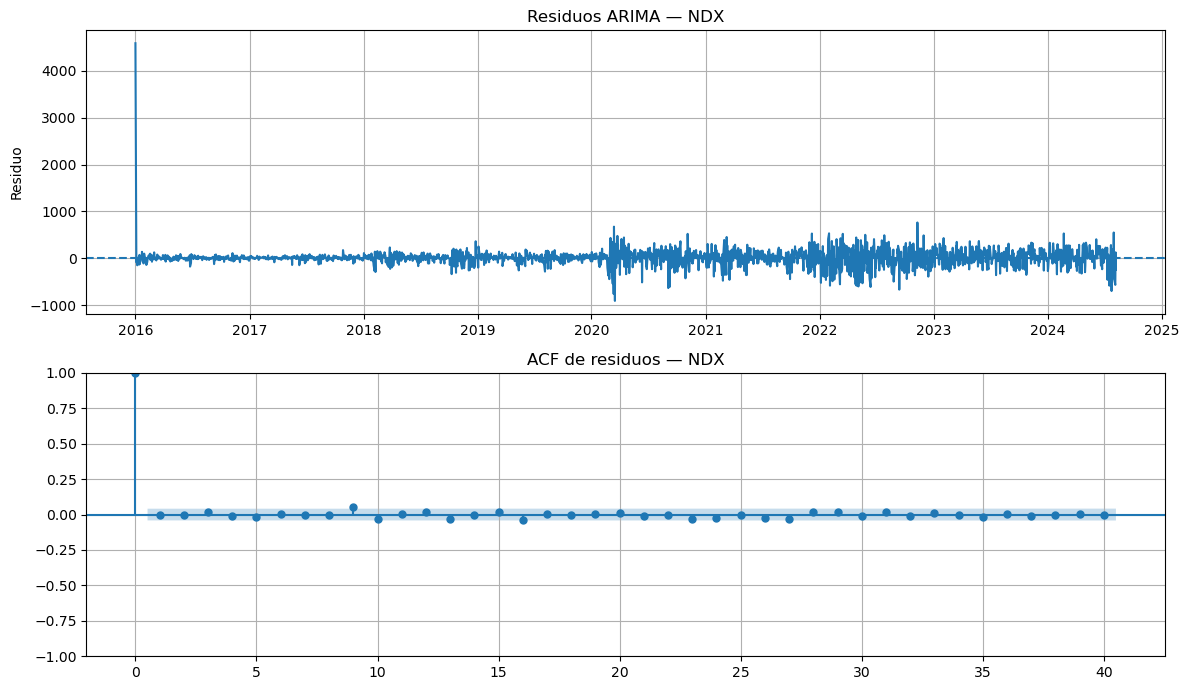

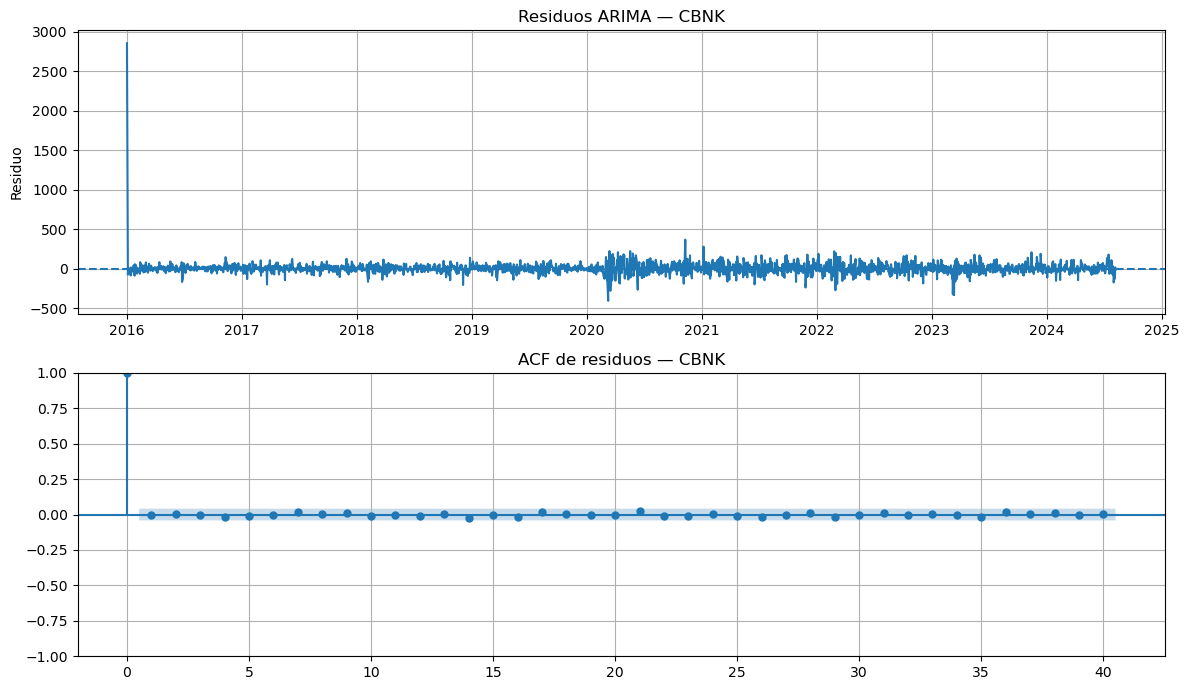

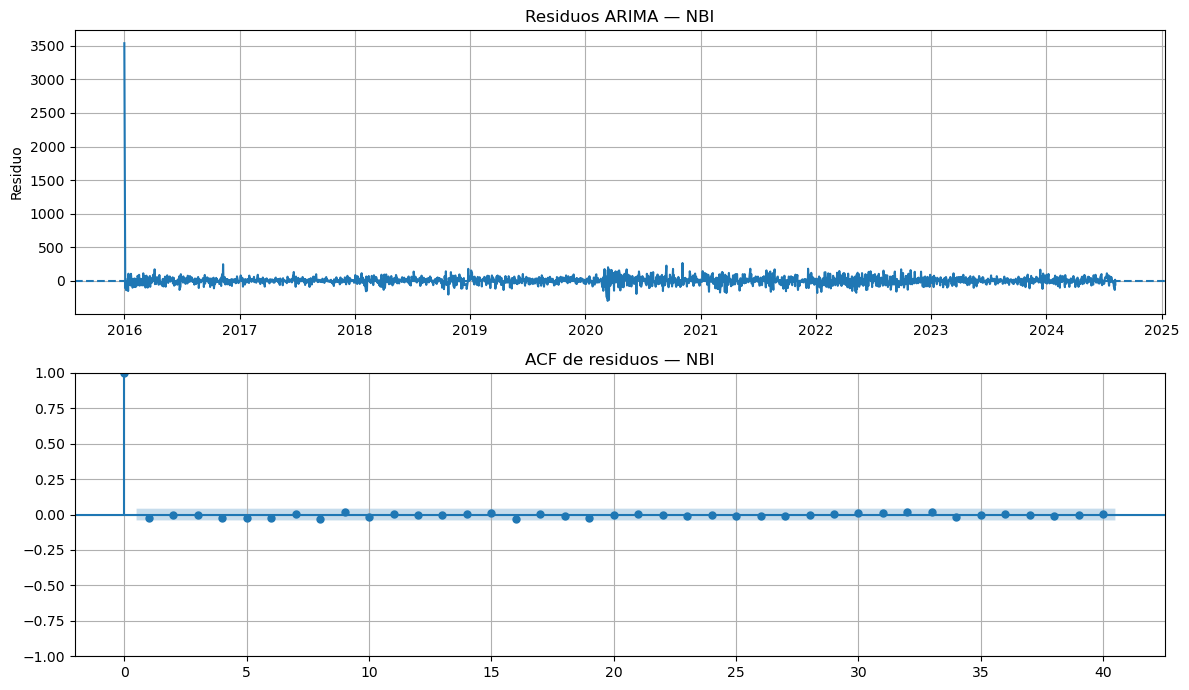

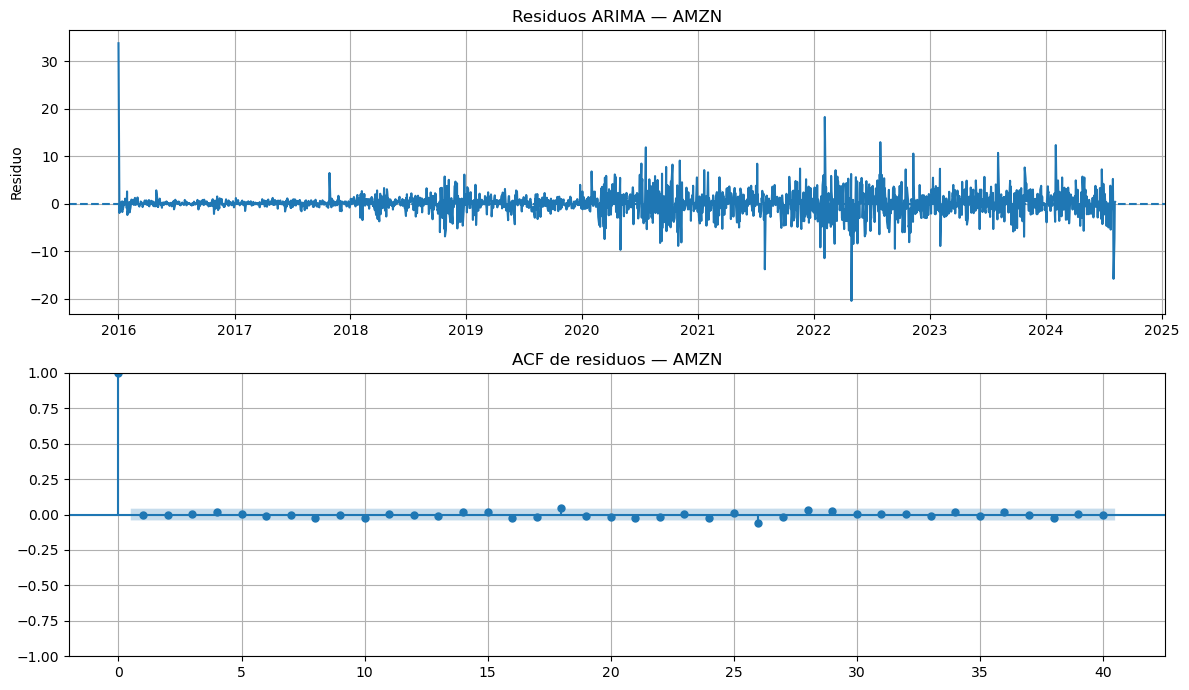

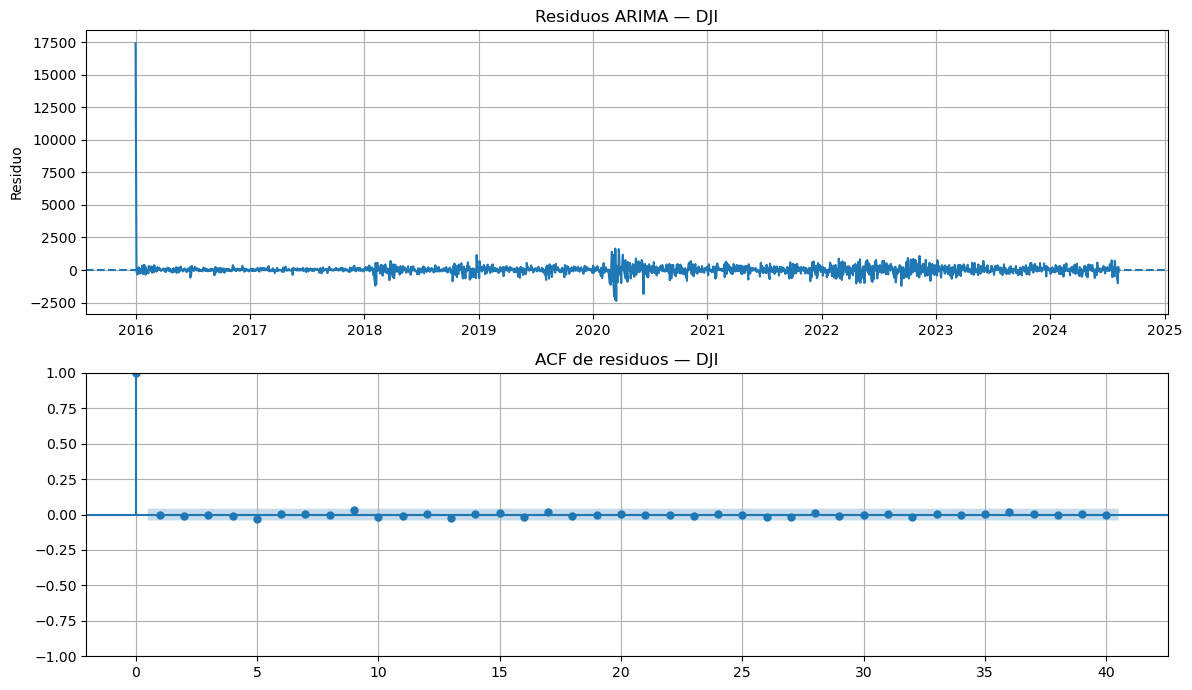

In [14]:
residuos = {}

for activo in tickers:
    
    resultado = modelos_arima[activo]
    
    resid = resultado.resid.dropna()
    
    residuos[activo] = resid
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    
    axes[0].plot(resid)
    axes[0].axhline(0, linestyle="--")
    axes[0].set_title(
        f"Residuos ARIMA — {activo}"
    )
    axes[0].set_ylabel("Residuo")
    
    plot_acf(
        resid,
        lags=40,
        ax=axes[1]
    )
    
    axes[1].set_title(
        f"ACF de residuos — {activo}"
    )
    
    plt.tight_layout()
    plt.show()

In [15]:
resultados_ljungbox = []
nivel_significancia = 0.05

for activo in tickers:
    resid = residuos[activo]
    
    prueba = acorr_ljungbox(
        resid,
        lags=[10, 20],
        return_df=True
    )
    
    pval_10 = prueba.loc[10, "lb_pvalue"]
    pval_20 = prueba.loc[20, "lb_pvalue"]
    
    hay_correlacion = "Sí" if (pval_10 < nivel_significancia) or (pval_20 < nivel_significancia) else "No"
    
    resultados_ljungbox.append({
        "Activo": activo,
        "p-value lag 10": round(pval_10, 4),
        "p-value lag 20": round(pval_20, 4),
        "Autocorrelación Residual": hay_correlacion
    })

df_ljungbox = pd.DataFrame(resultados_ljungbox)
display(df_ljungbox)

,Activo,p-value lag 10,p-value lag 20,Autocorrelación Residual
0,AAPL,0.0062,0.0216,Sí
1,NVDA,0.0009,0.0000,Sí
2,MSFT,0.0027,0.0057,Sí
3,GOOGL,0.0757,0.1014,No
4,SPX,0.7332,0.9297,No
5,NDX,0.3753,0.5403,No
6,CBNK,0.9912,0.9996,No
7,NBI,0.5463,0.8527,No
8,AMZN,0.9645,0.9023,No
9,DJI,0.8609,0.9809,No


### 14. Validación

In [16]:
def walk_forward_arima(
    train_serie,
    test_serie,
    order
):
    
    train_serie = train_serie.copy()
    test_serie = test_serie.copy()
    
    train_serie.name = "y"
    test_serie.name = "y"
    
    modelo = ARIMA(
        train_serie,
        order=order
    )
    
    resultado = modelo.fit()
    
    predicciones = []
    inferiores = []
    superiores = []
    
    for fecha, valor_real in test_serie.items():
        
        forecast = resultado.get_forecast(
            steps=1
        )
        
        pred = forecast.predicted_mean.iloc[0]
        intervalo = forecast.conf_int().iloc[0]
        
        predicciones.append(pred)
        inferiores.append(intervalo.iloc[0])
        superiores.append(intervalo.iloc[1])
        
        nueva_observacion = pd.Series(
            [valor_real],
            index=pd.DatetimeIndex([fecha]),
            name="y"
        )
        
        resultado = resultado.append(
            nueva_observacion,
            refit=False
        )
    
    return (
        pd.Series(
            predicciones,
            index=test_serie.index,
            name="Pronóstico"
        ),
        
        pd.Series(
            inferiores,
            index=test_serie.index,
            name="Límite inferior"
        ),
        
        pd.Series(
            superiores,
            index=test_serie.index,
            name="Límite superior"
        )
    )

In [17]:
df_modelos = pd.DataFrame(resultados_modelos)
pronosticos = pd.DataFrame(
    index=test.index
)

intervalos_inferiores = pd.DataFrame(
    index=test.index
)

intervalos_superiores = pd.DataFrame(
    index=test.index
)

tiempos_walk_forward = []

inicio_total = time.perf_counter()

for activo in tickers:
    
    print(f"Pronosticando {activo}...")
    
    inicio_activo = time.perf_counter()
    
    modelo_info = df_modelos[
        df_modelos["Activo"] == activo
    ].iloc[0]
    
    orden = (
        int(modelo_info["p"]),
        int(modelo_info["d"]),
        int(modelo_info["q"])
    )
    
    pred, inf, sup = walk_forward_arima(
        train[activo],
        test[activo],
        orden
    )
    
    pronosticos[activo] = pred
    intervalos_inferiores[activo] = inf
    intervalos_superiores[activo] = sup
    
    tiempo_activo = (
        time.perf_counter() - inicio_activo
    )
    
    tiempos_walk_forward.append({
        "Activo": activo,
        "Tiempo (segundos)": tiempo_activo
    })
    
    print(
        f"   terminado en {tiempo_activo:.2f} s"
    )

tiempo_total = (
    time.perf_counter() - inicio_total
)

print(
    f"\nTiempo total: "
    f"{tiempo_total/60:.2f} minutos"
)

Pronosticando AAPL...
   terminado en 303.88 s
Pronosticando NVDA...
   terminado en 317.31 s
Pronosticando MSFT...
   terminado en 309.65 s
Pronosticando GOOGL...
   terminado en 300.58 s
Pronosticando SPX...
   terminado en 314.44 s
Pronosticando NDX...
   terminado en 301.95 s
Pronosticando CBNK...
   terminado en 273.25 s
Pronosticando NBI...
   terminado en 269.37 s
Pronosticando AMZN...
   terminado en 277.19 s
Pronosticando DJI...
   terminado en 283.60 s

Tiempo total: 49.19 minutos


### 15. Metricas

In [23]:
def calcular_mape(y_real, y_pred):
    
    return (
        np.mean(
            np.abs(
                (y_real - y_pred) / y_real
            )
        ) * 100
    )


metricas = []

for activo in tickers:
    
    real = test[activo]
    pred = pronosticos[activo]
    
    rmse = np.sqrt(
        mean_squared_error(
            real,
            pred
        )
    )
    
    mae = mean_absolute_error(
        real,
        pred
    )
    
    mape = calcular_mape(
        real,
        pred
    )
    
    metricas.append({
        "Activo": activo,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    })

df_metricas = pd.DataFrame(metricas)

display(
    df_metricas
)

,Activo,RMSE,MAE,MAPE (%)
0,AAPL,4.206763,2.856010,1.149381
1,NVDA,4.736998,3.552502,2.227894
2,MSFT,7.502682,5.036474,1.155357
3,GOOGL,5.088378,3.438050,1.383815
4,SPX,59.761063,42.237591,0.665251
5,NDX,308.542527,221.777643,0.939580
6,CBNK,66.202808,45.782945,1.012173
7,NBI,71.287531,52.599671,1.014026
8,AMZN,4.546093,3.228162,1.462559
9,DJI,403.130308,292.601879,0.641430


### 16. Graficos

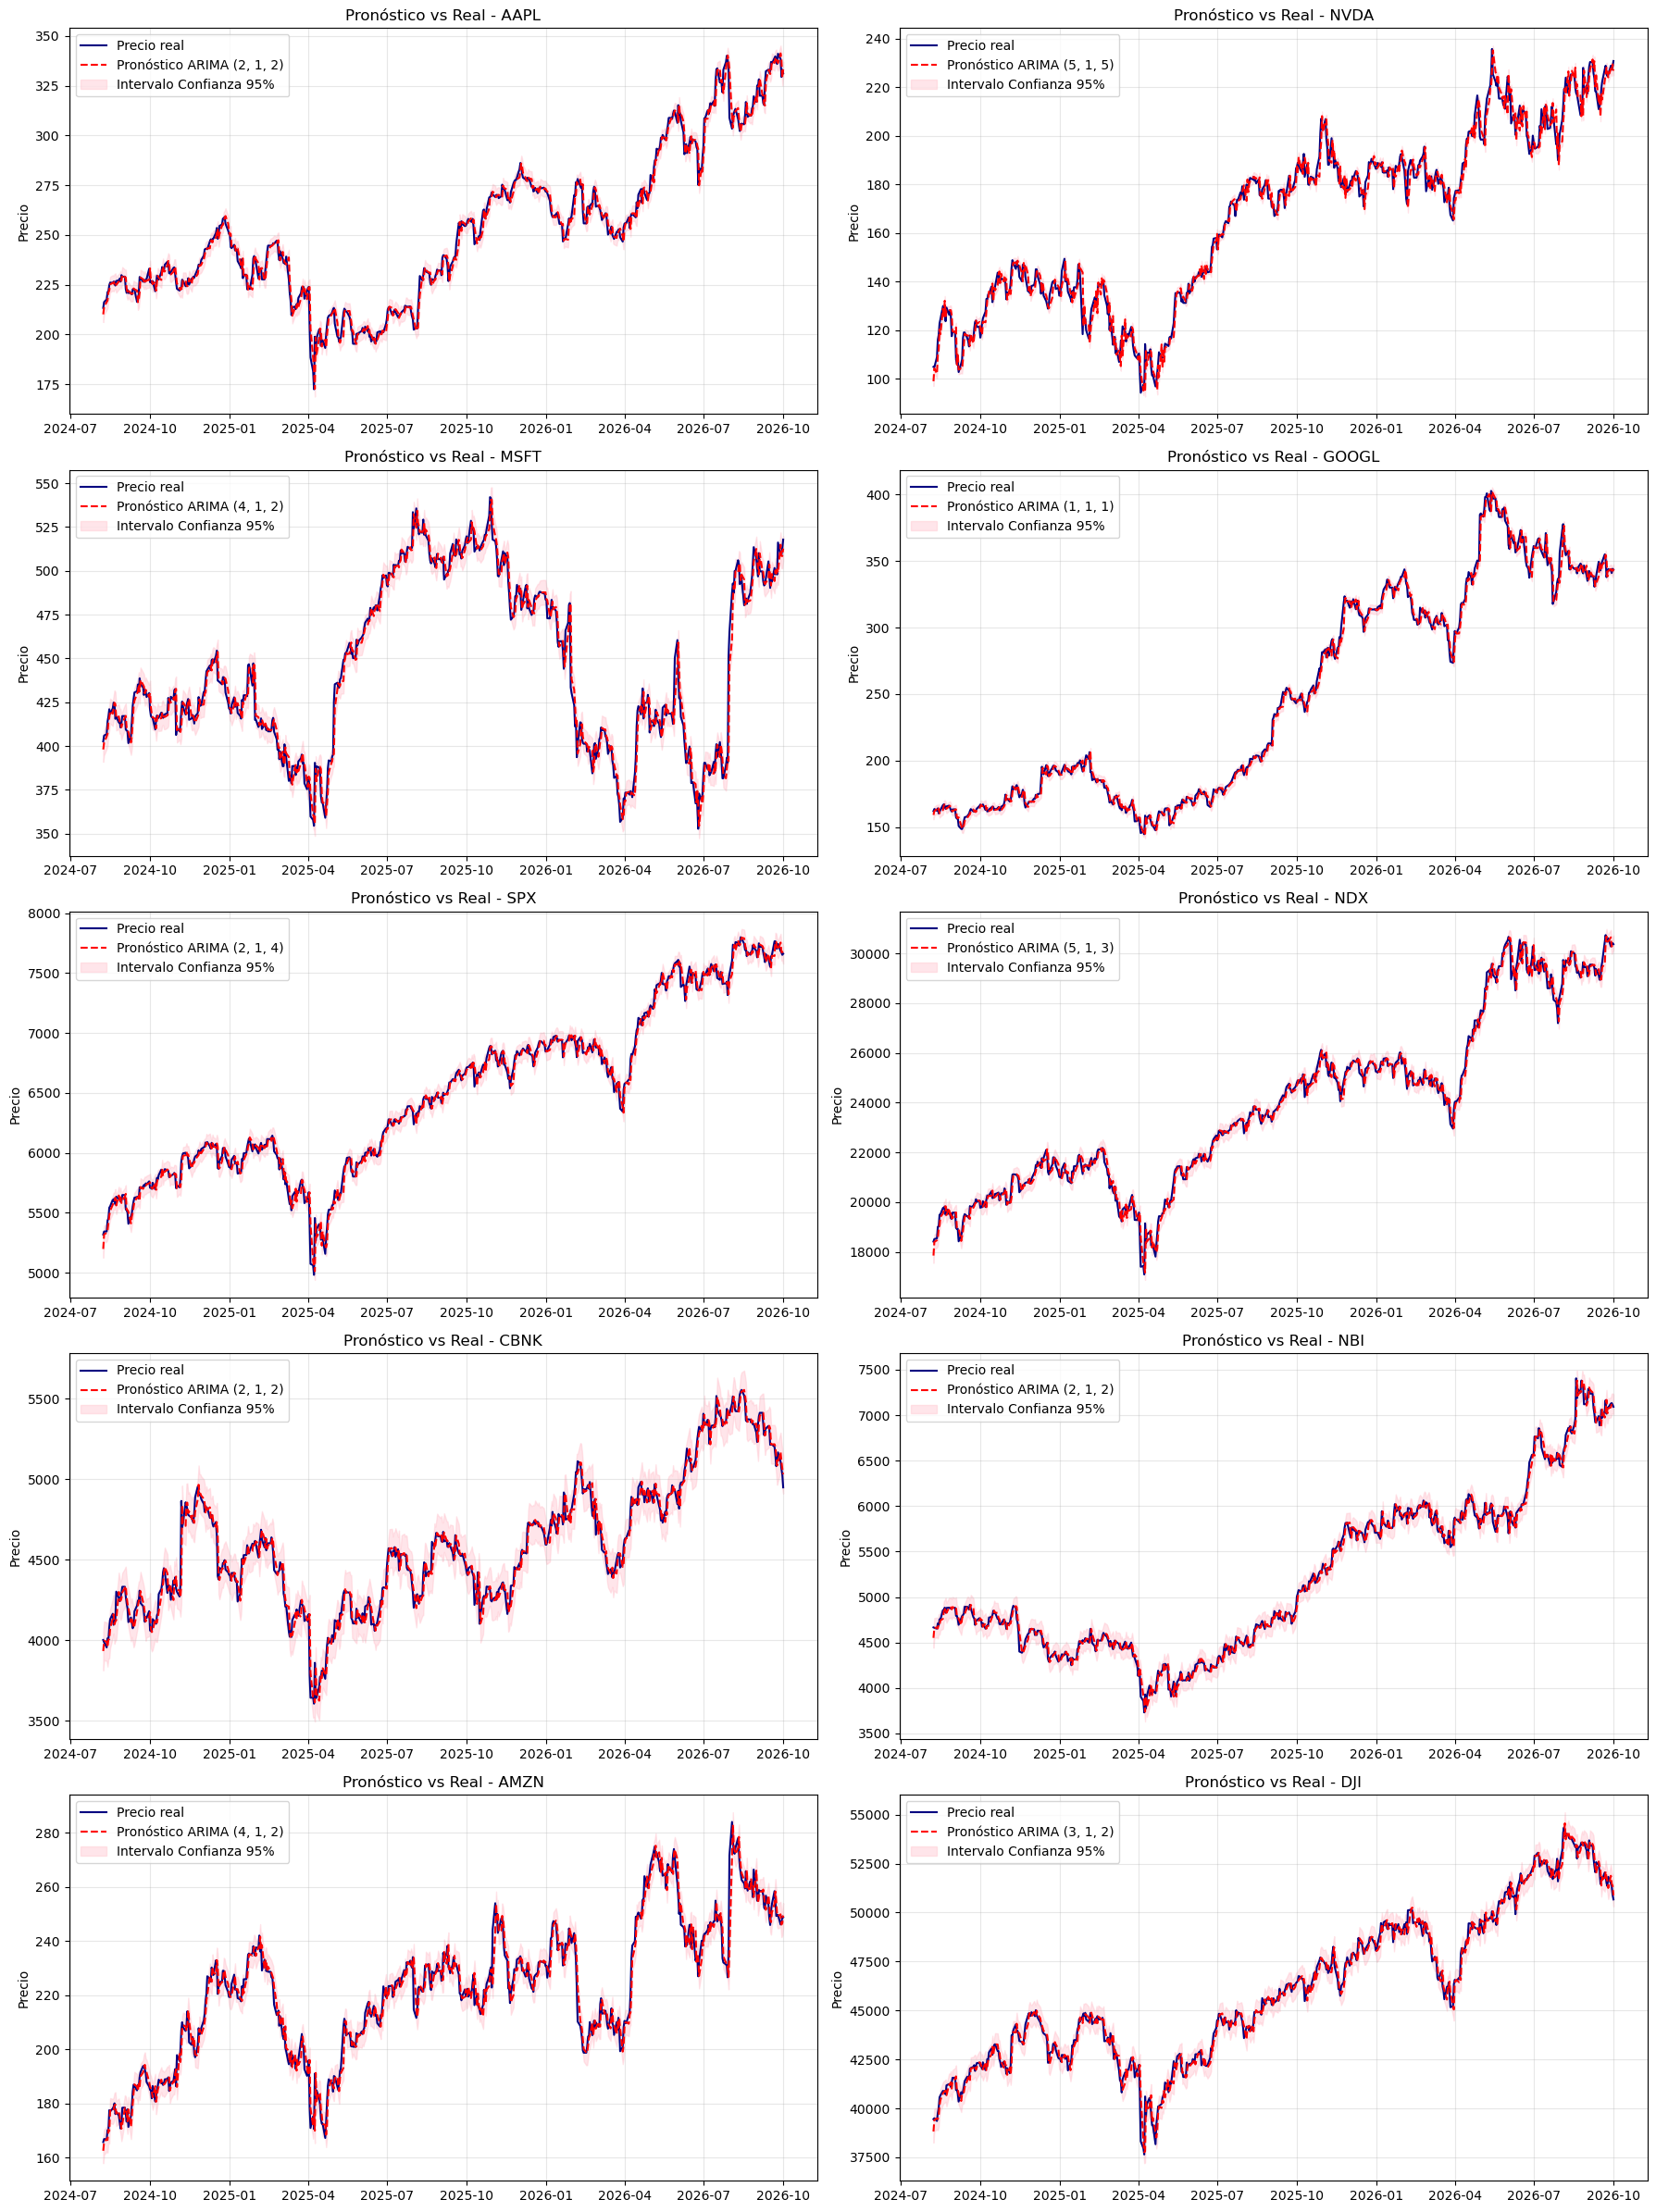

In [19]:
fig, axes = plt.subplots(5, 2, figsize=(18, 24))
axes = axes.flatten()

for i, activo in enumerate(tickers):
    ax = axes[i]
    
    precio_real = test[activo]
    pronostico = pronosticos[activo]  # Nombre corregido
    lim_inf = intervalos_inferiores[activo] # Intervalo inferior
    lim_sup = intervalos_superiores[activo] # Intervalo superior
    
    # Extraer el orden del modelo para la leyenda
    orden = modelos_arima[activo].model.order if activo in modelos_arima else ""
    
    # Gráficas
    ax.plot(precio_real.index, precio_real, label="Precio real", color="navy")
    ax.plot(pronostico.index, pronostico, label=f"Pronóstico ARIMA {orden}", linestyle="--", color="red")
    
    # Agregar la banda de confianza
    ax.fill_between(pronostico.index, lim_inf, lim_sup, color='pink', alpha=0.4, label='Intervalo Confianza 95%')
    
    ax.set_title(f"Pronóstico vs Real - {activo}")
    ax.set_ylabel("Precio")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

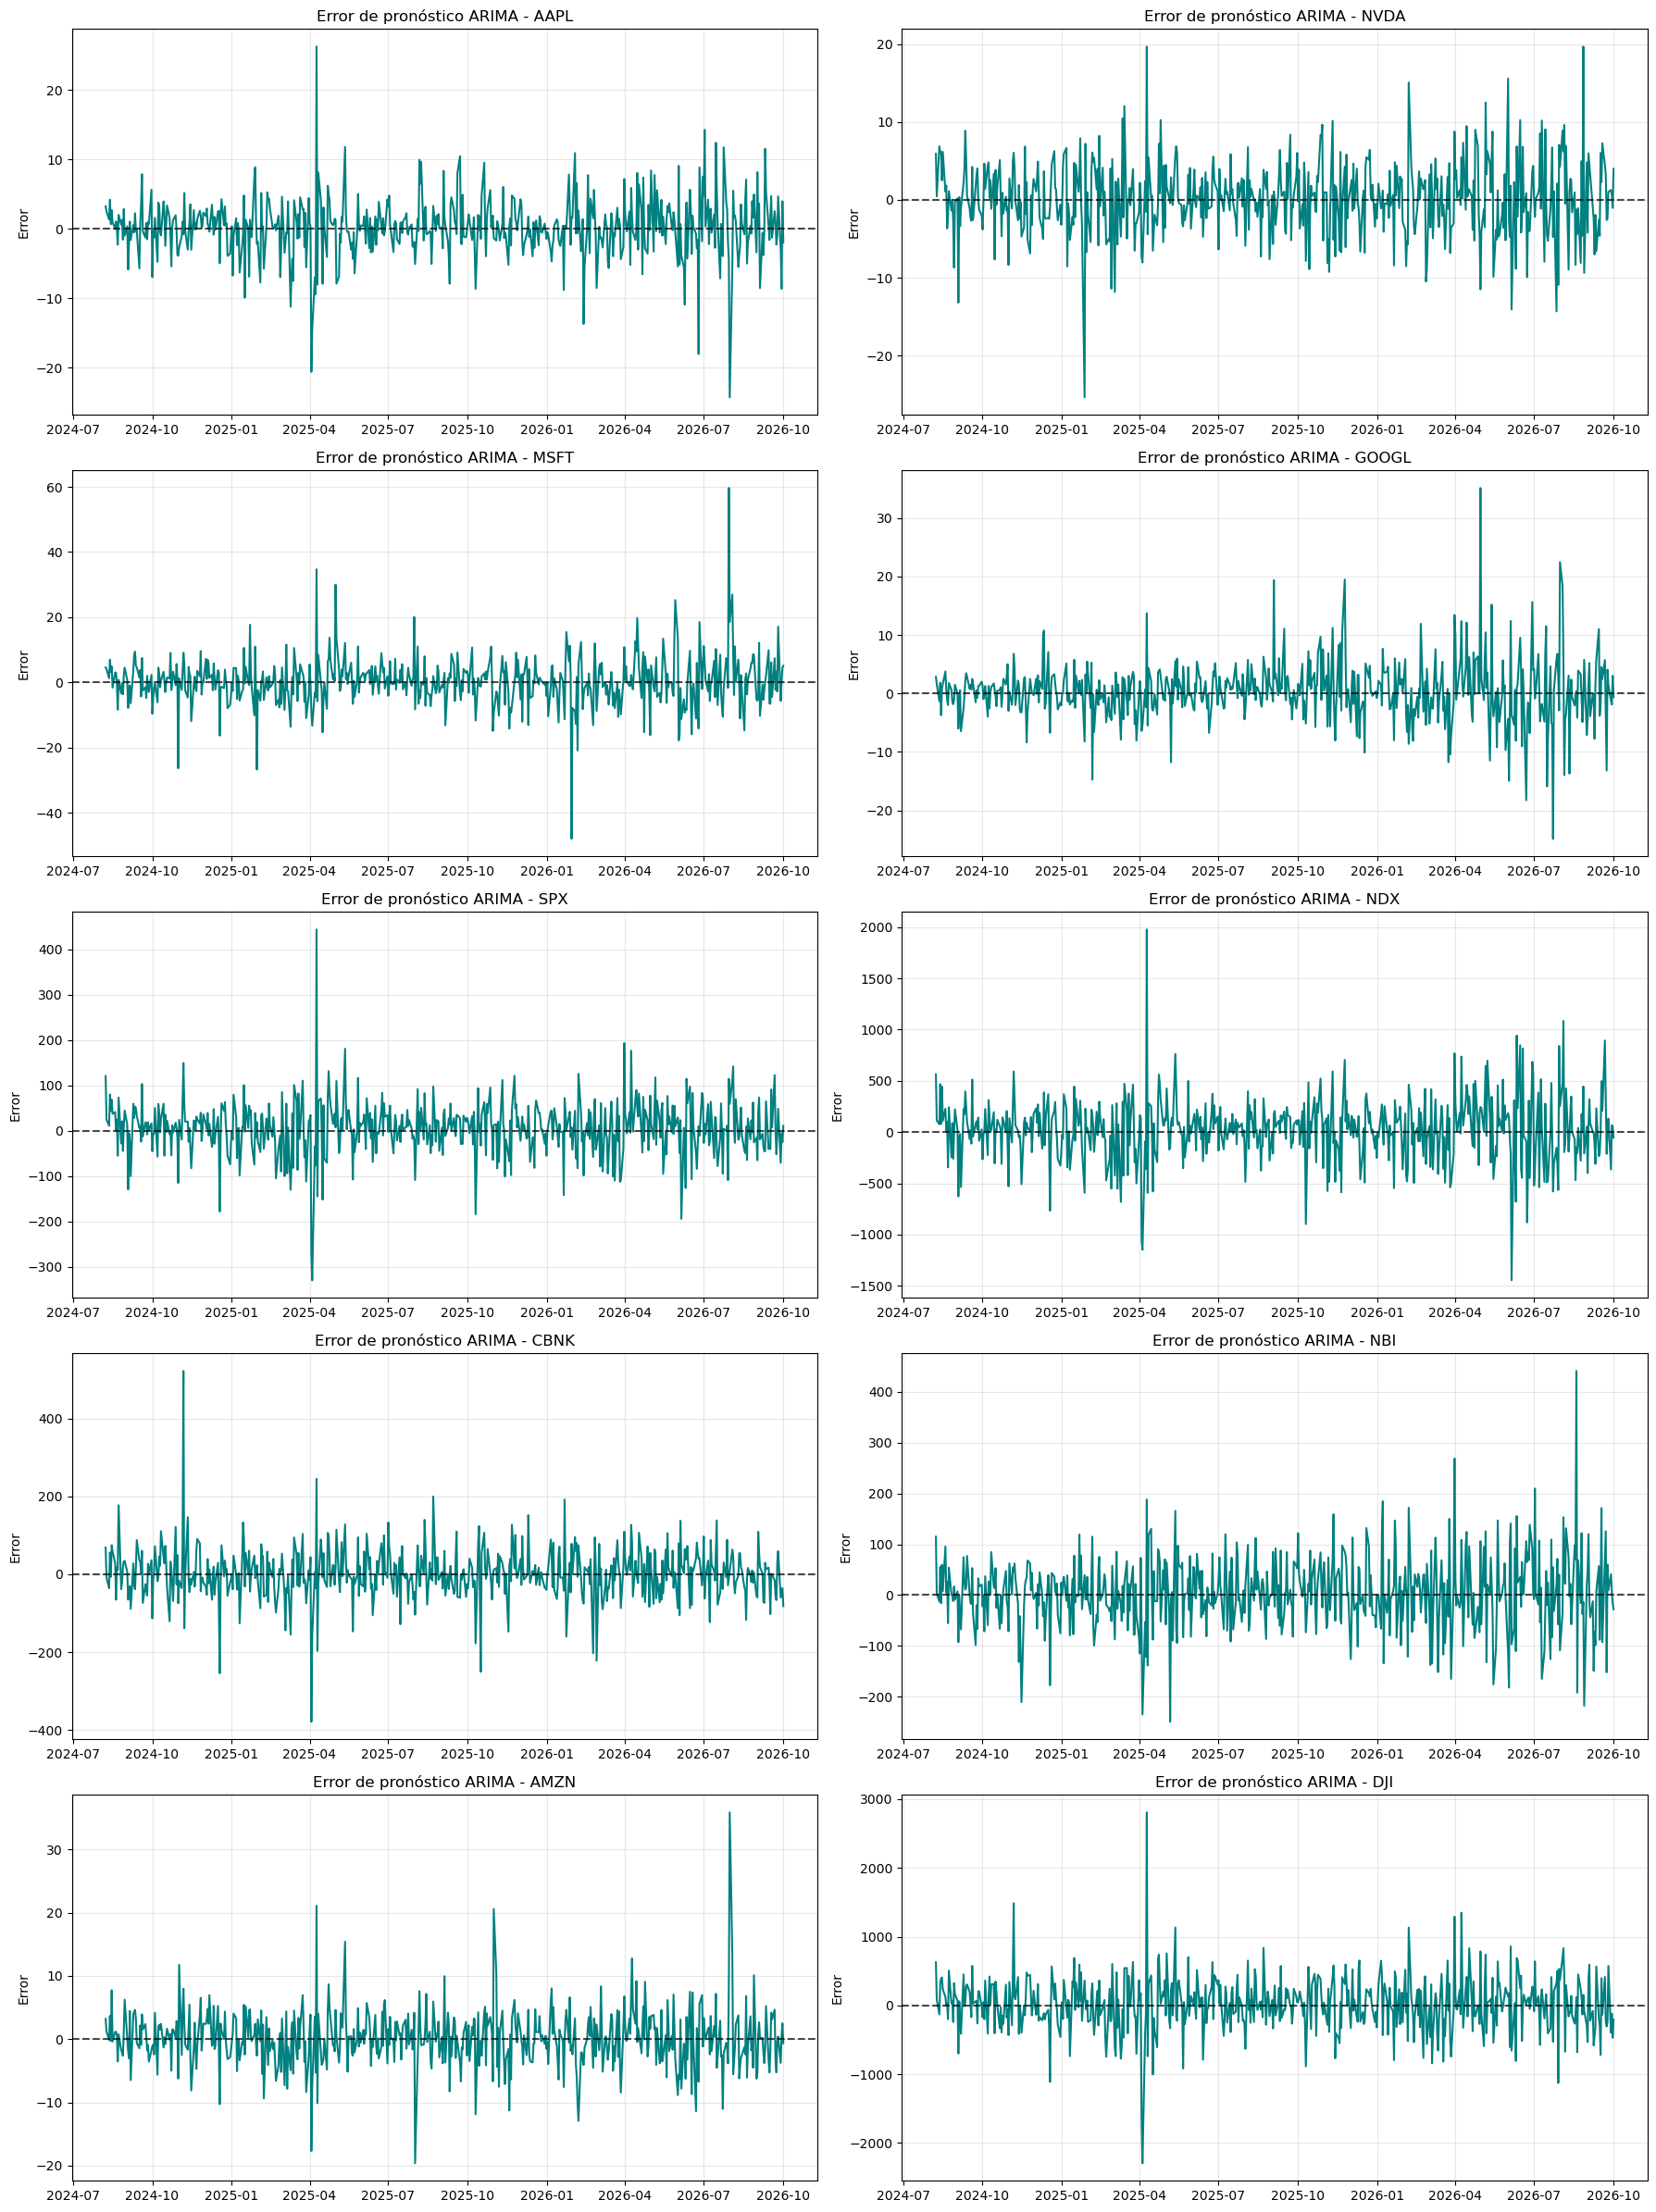

In [20]:
fig, axes = plt.subplots(5, 2, figsize=(18, 24))
axes = axes.flatten()

for i, activo in enumerate(tickers):
    ax = axes[i]
    
    precio_real = test[activo]
    pronostico = pronosticos[activo]  # Nombre corregido
    error_pronostico = precio_real - pronostico
    
    ax.plot(error_pronostico.index, error_pronostico, color="teal")
    ax.axhline(0, color="black", linestyle="--", alpha=0.7)
    
    ax.set_title(f"Error de pronóstico ARIMA - {activo}")
    ax.set_ylabel("Error")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()